# ArA-DF 2026 (Track 1): EDA, preprocessing and full fine-tuning — Nabra
**Part A (sections 0–11):** data analysis and preprocessing decisions. Run once; section 10b saves the clean manifests to the team Drive folder `nabra/artifacts/aradf_eda`.

**Part B (section 12):** full fine-tuning of XLS-R 300M and WavLM-Large with the official AASIST back end. Part B is self-contained: in a new Colab session, run section 12 only (from 12.1).

Labels: 1 = bona fide (real), 0 = spoof (fake). Scores: higher = more bona fide.

## 0. Setup
Install packages, log in to Hugging Face, set paths.

In [1]:
!pip -q install huggingface_hub soundfile pyarrow

In [2]:
import os, io, re, json, glob, time, shutil, hashlib, sys
from collections import defaultdict
import numpy as np, pandas as pd, soundfile as sf
import matplotlib.pyplot as plt
from huggingface_hub import HfApi, hf_hub_download, login
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

# ---------------- settings ----------------
REPO_ID    = "ArabicSpeech/ArA-DF-2026"
REVISION   = "2b1f042dc166b1d372841cb0d7110661ea5b2a93"   # pinned dataset version
LOCAL_ROOT = None                                   # folder of the dataset if already downloaded on your computer (None = download from the Hub)
AUDIO_ROOT = "aradf_audio"                          # where clips are extracted (local folder or Colab disk)
EXTRACT_SPLITS = ["train", "dev", "track-1_development_test", "track-2_development_test"]
MAX_SHARDS_PER_SPLIT = None                         # e.g. 1 for a quick test run
SEED = 42
# ------------------------------------------

os.makedirs(AUDIO_ROOT, exist_ok=True)
np.random.seed(SEED)

HF_TOKEN = None
try:
    from google.colab import userdata; HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN: login(HF_TOKEN)

def list_files():
    if LOCAL_ROOT:
        return sorted(os.path.relpath(p, LOCAL_ROOT).replace(os.sep, "/")
                      for p in glob.glob(f"{LOCAL_ROOT}/**/*", recursive=True) if os.path.isfile(p))
    return sorted(HfApi().list_repo_files(REPO_ID, repo_type="dataset", revision=REVISION, token=HF_TOKEN))

def fetch(path):
    return os.path.join(LOCAL_ROOT, path) if LOCAL_ROOT else hf_hub_download(REPO_ID, path, repo_type="dataset", revision=REVISION, token=HF_TOKEN)

FILES = list_files()
print(len(FILES), "files in repo")

114 files in repo


**Result:** Setup OK; connected to the Hub (114 files in the repo).

## 1. Load metadata
All 6 labeled splits in one table; dialect and gender parsed from train/dev file names.

In [3]:
SPLITS = ["train", "dev", "track-1_development_test", "track-2_development_test", "track-1_test", "track-2_test"]
def meta_path(s):
    return f"metadata/{s}.parquet" if s in ("train", "dev") else f"metadata_labeled/{s}.parquet"

ALL = pd.concat([pd.read_parquet(fetch(meta_path(s))).assign(cfg=s) for s in SPLITS], ignore_index=True)
ALL["label_name"] = ALL["label"].map({1: "bonafide", 0: "spoof"})

def parse_name(i):
    p = str(i).split("_")
    return (p[0], p[1]) if len(p) >= 4 and p[2] in ("train", "dev") else ("unknown", "unknown")
ALL[["dialect", "gender"]] = pd.DataFrame(ALL["id"].map(parse_name).tolist(), index=ALL.index)
TD = ALL[ALL.cfg.isin(["train", "dev"])]
print(ALL.shape); ALL.head(3)

metadata/train.parquet: reconstructing file:   0%|          |  0.00B / 2.14MB            

metadata/train.parquet: downloading bytes:           |  0.00B            

metadata/dev.parquet: reconstructing file:   0%|          |  0.00B / 1.99MB            

metadata/dev.parquet: downloading bytes:           |  0.00B            

metadata_labeled/track-1_development_tes(…): reconstructing file:   0%|          |  0.00B / 1.52MB            

metadata_labeled/track-1_development_tes(…): downloading bytes:           |  0.00B            

... (4 outputs left out)

metadata_labeled/track-2_test.parquet: reconstructing file:   0%|          |  0.00B / 11.2MB            

metadata_labeled/track-2_test.parquet: downloading bytes:           |  0.00B            

(345672, 14)


,id,file_name,split,label,duration_sec,sample_rate,channels,subtype,sha256,flac_bytes,cfg,label_name,dialect,gender
0,EGY_Female_train_0001871,data/train/train-000000.tar::EGY_Female_train_...,train,0,5.110,16000,1,PCM_16,de0c011b67878c539680fed53c9b4eebcf822c23da9983...,66690,train,spoof,EGY,Female
1,EGY_Female_train_0002162,data/train/train-000000.tar::EGY_Female_train_...,train,1,13.480,16000,1,PCM_16,b4d46031821fecf5f09e341158c51f61503f88eaf0833c...,231991,train,bonafide,EGY,Female
2,EGY_Female_train_0028818,data/train/train-000000.tar::EGY_Female_train_...,train,1,12.121,16000,1,PCM_16,cb12ac1d895b30bc69a9cbd0ae727e2825493c260ef144...,219006,train,bonafide,EGY,Female


**Result:** 345,672 labeled clips in 6 splits; counts match the paper. Dialect and gender parsed from train/dev ids.

## 2. Metadata EDA
Class, dialect and gender counts, and duration per split, label and dialect.

label_name                bonafide   spoof     All
cfg                                               
dev                           6952   14048   21000
track-1_development_test      4097   11926   16023
track-1_test                 36903  107307  144210
track-2_development_test      3510   10683   14193
track-2_test                 31490   96256  127746
train                         7500   15000   22500
All                          90452  255220  345672 

label_name     bonafide  spoof    All
cfg   dialect                        
dev   EGY          1452   3077   4529
      Gulf         5015   9997  15012
      MSA           485    974   1459
train EGY          2500   5000   7500
      Gulf         2500   5000   7500
      MSA          2500   5000   7500
All               14452  29048  43500 

label_name             bonafide  spoof
cfg   dialect gender                  
dev   EGY     Female        373    794
              Male         1024   2184
              Unknown        55     99


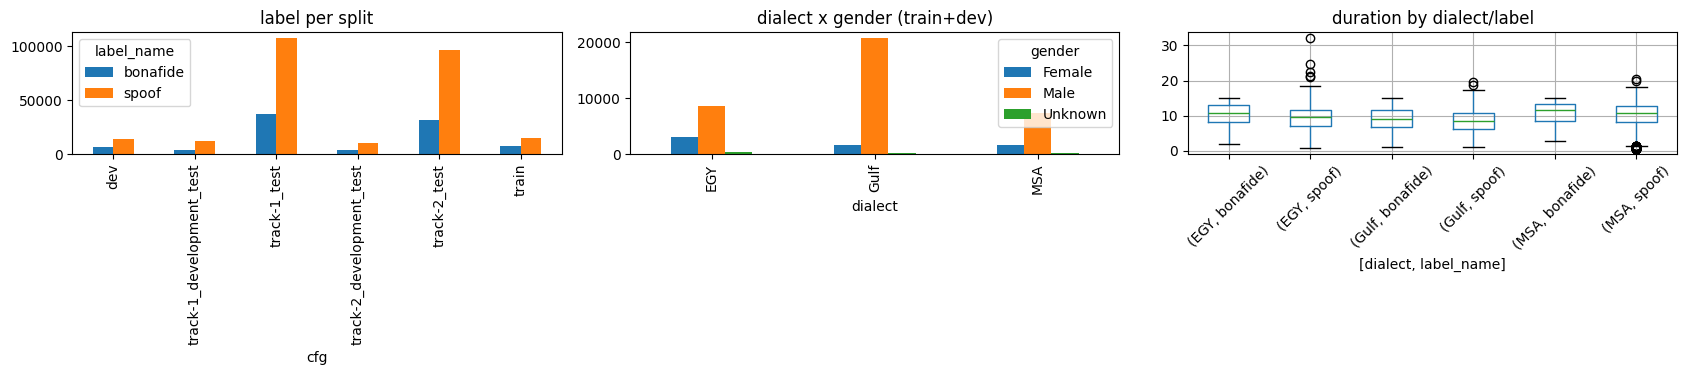

In [4]:
print(pd.crosstab(ALL.cfg, ALL.label_name, margins=True), "\n")
print(pd.crosstab([TD.cfg, TD.dialect], [TD.label_name], margins=True), "\n")
print(pd.crosstab([TD.cfg, TD.dialect, TD.gender], TD.label_name), "\n")
print(TD.groupby(["cfg", "dialect", "label_name"])["duration_sec"].describe(percentiles=[.05, .5, .95]).round(2))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
pd.crosstab(ALL.cfg, ALL.label_name).plot.bar(ax=ax[0], title="label per split")
pd.crosstab([TD.dialect], [TD.gender]).plot.bar(ax=ax[1], title="dialect x gender (train+dev)")
TD.boxplot("duration_sec", by=["dialect", "label_name"], ax=ax[2], rot=45); ax[2].set_title("duration by dialect/label")
plt.suptitle(""); plt.tight_layout(); plt.show()

**Result:** Bona fide : spoof is about 1 : 2 in every split. Train is balanced over EGY/Gulf/MSA (7,500 each); dev is 71% Gulf. About 81% of train clips are male. Spoofs are slightly shorter (median ≈9.6 s vs ≈10.6 s).

In [5]:
# duration outliers: clips longer than the 15 s eligibility limit or shorter than 1 s
long_ = ALL[ALL.duration_sec > 15.5]; short_ = ALL[ALL.duration_sec < 1.0]
print("clips > 15.5 s:"); print(pd.crosstab(long_.cfg, long_.label_name))
print("\nclips < 1 s:");   print(pd.crosstab(short_.cfg, short_.label_name))
print("\nlongest clips:"); print(ALL.nlargest(8, "duration_sec")[["cfg", "id", "label_name", "duration_sec"]])

clips > 15.5 s:
label_name                bonafide  spoof
cfg                                      
dev                              0     15
track-1_development_test         0    187
track-1_test                     5   1583
track-2_development_test         0    161
track-2_test                     0   1315
train                            0     51

clips < 1 s:
label_name                spoof
cfg                            
dev                           6
track-1_development_test     10
track-1_test                 97
track-2_development_test      5
track-2_test                 66
train                        33

longest clips:
                             cfg            id label_name  duration_sec
111824              track-1_test  test_3362593      spoof    106.752000
323694              track-2_test  test_8448417      spoof    106.718937
49574   track-1_development_test  test_0375788      spoof     95.040000
52912   track-1_development_test  test_0590156      spoof     95.040000
53

**Result:** Almost all clips over 15.5 s or under 1 s are spoof (only 5 long bona fide clips, in Track 1 test). Longest: 106.8 s (final tests) and 95.04 s (Track 1 dev-test).

## 3. Data pipeline functions
Extraction, loading, cropping, augmentation, PyTorch Dataset and EER, used by the rest of the notebook and by the model code.

In [6]:
"""ArA-DF 2026 data pipeline (Nabra project).
Labels: 1 = bona fide (real), 0 = spoof (fake). Audio: 16 kHz mono.
"""
import os, io, json, tarfile
import numpy as np, pandas as pd, soundfile as sf

SR = 16000
REPO_ID = "ArabicSpeech/ArA-DF-2026"

# ---------- extraction (run once per Colab session) ----------
def iter_tar(tar_path):
    """Yield (id, flac_bytes) from a WebDataset tar shard."""
    with tarfile.open(tar_path) as tf:
        for m in tf:
            if m.isfile() and m.name.endswith(".flac"):
                yield os.path.basename(m.name)[:-5], tf.extractfile(m).read()

def prepare_audio(splits, audio_root, keep_ids=None, token=None, max_shards=None, on_clip=None):
    """Download tar shards from the Hub and write <audio_root>/<split>/<id>.flac.
    keep_ids: optional set of ids to keep. on_clip(split, id, flac_bytes): optional callback."""
    from huggingface_hub import HfApi, hf_hub_download
    files = HfApi().list_repo_files(REPO_ID, repo_type="dataset", token=token)
    for split in splits:
        tars = sorted(f for f in files if f.startswith(f"data/{split}/") and f.endswith(".tar"))[:max_shards]
        os.makedirs(f"{audio_root}/{split}", exist_ok=True)
        for t in tars:
            local = hf_hub_download(REPO_ID, t, repo_type="dataset", token=token)
            extract_tar(local, split, audio_root, keep_ids, on_clip)

def extract_tar(local_tar, split, audio_root, keep_ids=None, on_clip=None):
    n = 0
    for cid, flac in iter_tar(local_tar):
        if on_clip: on_clip(split, cid, flac)
        if keep_ids is not None and cid not in keep_ids: continue
        p = f"{audio_root}/{split}/{cid}.flac"
        if not os.path.exists(p):
            with open(p, "wb") as f: f.write(flac)
        n += 1
    return n

# ---------- waveform processing ----------
def load_wave(path):
    x, sr = sf.read(path, dtype="float32", always_2d=False)
    if x.ndim > 1: x = x.mean(1)
    assert sr == SR, f"{path}: sr={sr}"
    return x

def trim_silence(x, top_db=40.0, frame=400, hop=160):
    """Remove leading/trailing frames quieter than (max frame energy - top_db)."""
    if len(x) < frame: return x
    nf = 1 + (len(x) - frame) // hop
    idx = np.arange(frame)[None, :] + hop * np.arange(nf)[:, None]
    e = 10 * np.log10((x[idx] ** 2).mean(1) + 1e-10)
    v = np.flatnonzero(e > e.max() - top_db)
    return x[v[0] * hop: v[-1] * hop + frame] if len(v) else x

def rms_normalize(x, target_dbfs=-23.0):
    rms = np.sqrt(np.mean(x ** 2) + 1e-12)
    return np.clip(x * (10 ** (target_dbfs / 20) / rms), -1, 1).astype(np.float32)

def crop_or_pad(x, n, train, rng=np.random):
    """Fixed length n. Train: random crop; otherwise start crop. Short clips: repeat-pad."""
    if len(x) == 0: return np.zeros(n, np.float32)
    if len(x) < n: x = np.tile(x, int(np.ceil(n / len(x))))
    if len(x) == n: return x[:n]
    start = rng.randint(0, len(x) - n + 1) if train else 0
    return x[start:start + n]

def augment(x, rng=np.random, p=0.5):
    """Light channel augmentation (train only): gain, additive noise, telephone band."""
    from scipy.signal import resample_poly, butter, sosfilt
    if rng.rand() < p:                                   # gain +-6 dB
        x = x * 10 ** (rng.uniform(-6, 6) / 20)
    if rng.rand() < p:                                   # white noise, SNR 10-40 dB
        snr = rng.uniform(10, 40); pw = np.mean(x ** 2) + 1e-12
        x = x + rng.randn(len(x)).astype(np.float32) * np.sqrt(pw / 10 ** (snr / 10))
    if rng.rand() < p * 0.5:                             # telephone: 8 kHz + 300-3400 Hz band
        y = resample_poly(x, 1, 2)
        y = sosfilt(butter(4, [300, 3400], btype="band", fs=8000, output="sos"), y)
        x = resample_poly(y, 2, 1)[:len(x)]
    return np.clip(x, -1, 1).astype(np.float32)

def make_windows(x, n):
    """Cover the WHOLE clip with windows of n samples (eval). Last window is aligned to the clip end."""
    if len(x) <= n: return crop_or_pad(x, n, train=False)[None, :]
    starts = list(range(0, len(x) - n + 1, n))
    if starts[-1] + n < len(x): starts.append(len(x) - n)
    return np.stack([x[s:s + n] for s in starts])

# window = 64,600 samples (~4.04 s), same as the official baseline. Train: one random window per clip
# (a different part every epoch). Eval: the whole clip is split into windows and scores are averaged.
DEFAULT_CONFIG = dict(crop_sec=64600 / 16000, trim_silence=False, normalize="none", augment_p=0.5)

def clean_wave(x, cfg):
    if cfg.get("trim_silence"): x = trim_silence(x)
    if cfg.get("normalize") == "rms": x = rms_normalize(x)
    return x.astype(np.float32)

def preprocess(x, cfg, train, rng=np.random):
    """Train: one window [n] (random crop + augmentation). Eval: all windows [W, n], no augmentation."""
    x = clean_wave(x, cfg); n = int(round(cfg["crop_sec"] * SR))
    if not train: return make_windows(x, n).astype(np.float32)
    x = crop_or_pad(x, n, True, rng)
    if cfg.get("augment_p", 0) > 0: x = augment(x, rng, cfg["augment_p"])
    return x.astype(np.float32)

# ---------- PyTorch ----------
def make_dataset(manifest, audio_root, cfg, train):
    import torch
    df = manifest[manifest["keep"]].reset_index(drop=True)
    class AraDFDataset(torch.utils.data.Dataset):
        def __init__(self): self.df = df
        def __len__(self): return len(self.df)
        def __getitem__(self, i):
            r = self.df.iloc[i]
            x = preprocess(load_wave(os.path.join(audio_root, r["path"])), cfg, train)
            return torch.from_numpy(x), int(r["label"]), r["id"]
    return AraDFDataset()

def collate_windows(batch):
    """Eval batches: stack all windows of all clips; counts tells which windows belong to which clip."""
    import torch
    waves = torch.cat([b[0] for b in batch]); counts = [b[0].shape[0] for b in batch]
    return waves, torch.tensor([b[1] for b in batch]), [b[2] for b in batch], counts

def make_loader(ds, batch_size=16, train=True, balanced=False, num_workers=0):
    """Train: batches of single windows [B, n]; balanced=True gives ~50% real / 50% fake per batch.
    Eval: (windows [sum W, n], labels [B], ids, counts) via collate_windows."""
    import torch
    if not train:
        return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=False,
                                           num_workers=num_workers, collate_fn=collate_windows)
    sampler = None
    if balanced:
        y = ds.df["label"].to_numpy(dtype=np.int64); w = 1.0 / np.bincount(y, minlength=2)[y]
        sampler = torch.utils.data.WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double),
                                                         num_samples=len(y), replacement=True)
    return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=(sampler is None),
                                       sampler=sampler, num_workers=num_workers, drop_last=True)

def class_weights(manifest):
    """Weights for CrossEntropyLoss, order [spoof, bona fide]."""
    y = manifest[manifest["keep"]]["label"].values
    c = np.bincount(y, minlength=2); return (len(y) / (2 * c)).tolist()

# ---------- metric ----------
def compute_eer(labels, scores):
    """labels 1 = bona fide; scores higher = more bona fide. Returns EER in %."""
    from sklearn.metrics import roc_curve
    fpr, tpr, _ = roc_curve(np.asarray(labels), np.asarray(scores), pos_label=1)
    fnr = 1 - tpr; i = np.nanargmin(np.abs(fnr - fpr))
    return float(100 * (fpr[i] + fnr[i]) / 2)

In [7]:
import types
AD = types.SimpleNamespace(**{k: v for k, v in globals().items() if k in (
    "iter_tar", "extract_tar", "load_wave", "trim_silence", "rms_normalize", "crop_or_pad", "augment",
    "DEFAULT_CONFIG", "preprocess", "make_dataset", "make_loader", "class_weights", "compute_eer", "SR",
    "make_windows", "clean_wave", "collate_windows")})
print("pipeline functions ready")

pipeline functions ready


## 4. Extract audio and compute acoustic features
Writes every clip to `AUDIO_ROOT` and computes per-clip features (loudness, silence, clipping, bandwidth, SNR estimate). Takes ~20-30 min.

In [8]:
def acoustic_features(x16, sr=16000, frame=400, hop=160, nfft=512):
    x = x16.astype(np.float32) / 32768
    out = dict(peak=float(np.abs(x).max(initial=0)), clip_frac=float(np.mean(np.abs(x16) >= 32700)),
               dc=float(x.mean()) if len(x) else 0.0, rms_db=float(20 * np.log10(np.sqrt(np.mean(x ** 2) + 1e-12))))
    if len(x) < frame:
        return {**out, "lead_sil": 0.0, "trail_sil": 0.0, "speech_ratio": 0.0, "snr_est": 0.0, "rolloff95": 0.0, "centroid": 0.0}, None
    nf = 1 + (len(x) - frame) // hop
    fr = x[np.arange(frame)[None, :] + hop * np.arange(nf)[:, None]]
    e = 10 * np.log10((fr ** 2).mean(1) + 1e-10)
    v = e > max(e.max() - 40, -70)
    iv = np.flatnonzero(v)
    spec = np.abs(np.fft.rfft(fr[v] * np.hanning(frame), nfft)) ** 2 if v.any() else np.zeros((1, nfft // 2 + 1))
    ps = spec.mean(0); f = np.fft.rfftfreq(nfft, 1 / sr); c = np.cumsum(ps) / (ps.sum() + 1e-12)
    out.update(lead_sil=float(iv[0] * hop / sr) if len(iv) else 0.0,
               trail_sil=float((nf - 1 - iv[-1]) * hop / sr) if len(iv) else 0.0,
               speech_ratio=float(v.mean()), snr_est=float(np.percentile(e, 95) - np.percentile(e, 10)),
               rolloff95=float(f[min(np.searchsorted(c, 0.95), len(f) - 1)]), centroid=float((f * ps).sum() / (ps.sum() + 1e-12)))
    return out, np.log10(ps + 1e-12)

FEATS, LTAS = [], defaultdict(lambda: [np.zeros(257), 0])
lab_of = dict(zip(zip(ALL.cfg, ALL.id), ALL.label))

def on_clip(split, cid, flac):
    x, sr = sf.read(io.BytesIO(flac), dtype="int16", always_2d=False)
    if x.ndim > 1: x = x.mean(1).astype("int16")
    d, spec = acoustic_features(x, sr)
    FEATS.append(dict(cfg=split, id=cid, sr=sr, dur=len(x) / sr,
                      wav_md5=hashlib.md5(x.tobytes()).hexdigest(),
                      trim_md5=hashlib.md5(np.trim_zeros(np.where(np.abs(x) > 8, x, 0)).tobytes()).hexdigest(), **d))
    if spec is not None:
        k = (split, lab_of.get((split, cid))); LTAS[k][0] += spec; LTAS[k][1] += 1

t0 = time.time()
for split in EXTRACT_SPLITS:
    tars = sorted(f for f in FILES if f.startswith(f"data/{split}/") and f.endswith(".tar"))[:MAX_SHARDS_PER_SPLIT]
    os.makedirs(f"{AUDIO_ROOT}/{split}", exist_ok=True)
    for t in tars:
        n = AD.extract_tar(fetch(t), split, AUDIO_ROOT, on_clip=on_clip)
        print(f"{t}: {n} clips | {time.time() - t0:.0f}s")

F = pd.DataFrame(FEATS).merge(ALL[["cfg", "id", "label", "label_name", "dialect", "gender", "duration_sec", "sha256"]], on=["cfg", "id"], how="left")
print(F.shape, "| missing labels:", int(F.label.isna().sum()))

data/train/train-000000.tar: reconstructing file:   0%|          |  0.00B /  724MB            

data/train/train-000000.tar: downloading bytes:           |  0.00B            

data/train/train-000000.tar: 4096 clips | 70s


data/train/train-000001.tar: reconstructing file:   0%|          |  0.00B /  706MB            

data/train/train-000001.tar: downloading bytes:           |  0.00B            

data/train/train-000001.tar: 4096 clips | 156s


... (50 outputs left out)

data/track-2_development_test/track-2_development_test-000002.tar: 4096 clips | 1131s


data/track-2_development_test/track-2_de(…): reconstructing file:   0%|          |  0.00B /  331MB            

data/track-2_development_test/track-2_de(…): downloading bytes:           |  0.00B            

data/track-2_development_test/track-2_development_test-000003.tar: 1905 clips | 1164s
(73716, 22) | missing labels: 0


**Result:** Audio extracted for train, dev and both development tests: 73,716 clips, no missing labels. Final test splits: metadata only.

## 5. Acoustic EDA
Feature distributions per split and label.

                                     rms_db   peak  clip_frac   dc  lead_sil  trail_sil  speech_ratio  snr_est  rolloff95  centroid
cfg                      label_name                                                                                                
dev                      bonafide   -22.801  0.550        0.0 -0.0      0.00       0.00         0.908   34.834    1375.00   512.178
                         spoof      -23.191  0.544        0.0 -0.0      0.18       0.12         0.840   49.482    1375.00   514.854
track-1_development_test bonafide   -23.360  0.518        0.0 -0.0      0.00       0.02         0.903   35.481    1218.75   496.607
                         spoof      -24.386  0.487        0.0 -0.0      0.18       0.09         0.823   47.735    1187.50   473.607
track-2_development_test bonafide   -22.768  0.558        0.0 -0.0      0.00       0.00         0.972   27.527    1437.50   532.672
                         spoof      -23.657  0.519        0.0 -0.0      0.14

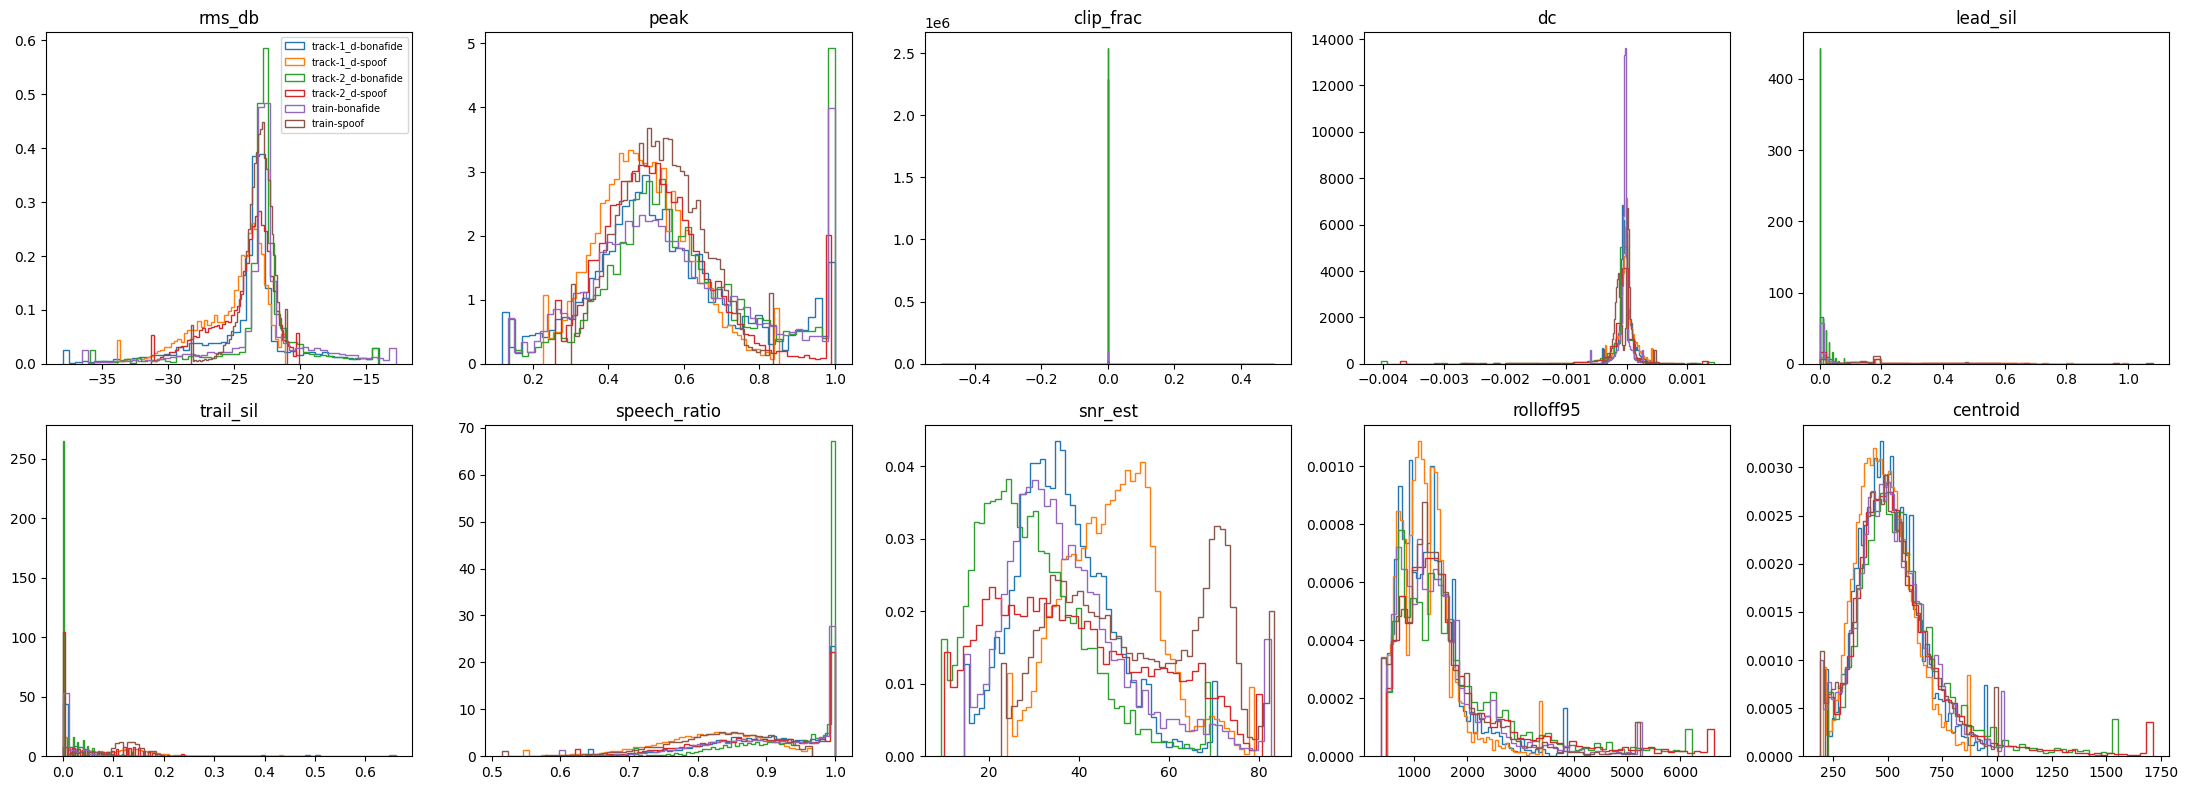

In [9]:
COLS = ["rms_db", "peak", "clip_frac", "dc", "lead_sil", "trail_sil", "speech_ratio", "snr_est", "rolloff95", "centroid"]
print(F.groupby(["cfg", "label_name"])[COLS].median().round(3))

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for a, c in zip(axes.ravel(), COLS):
    for (s, l), d in F.groupby(["cfg", "label_name"]):
        if s in ("train", "track-1_development_test", "track-2_development_test"):
            a.hist(d[c].clip(*d[c].quantile([.01, .99])), bins=50, histtype="step", density=True, label=f"{s[:9]}-{l}")
    a.set_title(c)
axes[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

**Result:** Spoofs have leading (≈0.18 s) and trailing (≈0.12 s) silence; bona fide has almost none. Spoofs also have higher SNR (≈49 vs ≈35 dB) and lower speech ratio. Loudness and spectral centroid are similar.

In [10]:
# 5b. Acoustic features by dialect and gender (train + dev)
D = F[F.cfg.isin(["train", "dev"])]
FEATS5 = ["rms_db", "lead_sil", "trail_sil", "speech_ratio", "snr_est"]
print(D.groupby(["dialect", "label_name"])[FEATS5].median().round(3), "\n")
print(D.groupby(["gender", "label_name"])[FEATS5].median().round(3), "\n")
rows = []
for dl, d in D.groupby("dialect"):
    if d.label.nunique() < 2: continue
    for c in FEATS5:
        e = AD.compute_eer(d.label.astype(int), d[c]); rows.append(dict(dialect=dl, feature=c, EER=round(min(e, 100 - e), 1)))
print("Single-feature EER per dialect (lower = stronger shortcut):")
print(pd.DataFrame(rows).pivot(index="feature", columns="dialect", values="EER"))

                    rms_db  lead_sil  trail_sil  speech_ratio  snr_est
dialect label_name                                                    
EGY     bonafide   -21.927      0.00       0.00         0.962   31.310
        spoof      -23.172      0.18       0.12         0.836   47.648
Gulf    bonafide   -22.830      0.00       0.00         0.901   35.895
        spoof      -23.234      0.18       0.12         0.842   49.284
MSA     bonafide   -22.704      0.00       0.00         0.855   42.597
        spoof      -22.877      0.19       0.12         0.829   63.043 

                    rms_db  lead_sil  trail_sil  speech_ratio  snr_est
gender  label_name                                                    
Female  bonafide   -22.873      0.00       0.00         0.961   30.916
        spoof      -23.170      0.17       0.12         0.858   43.066
Male    bonafide   -22.763      0.00       0.00         0.900   35.858
        spoof      -23.134      0.18       0.12         0.835   51.984
Unkn

**Result:** The silence pattern is the same in every dialect and gender (lead/trail EER 14-16%), so it comes from the TTS systems, not from one dialect.

## 6. Long-term average spectrum
Average spectrum per split and label; shows bandwidth / channel differences (e.g. codecs in the test sets).

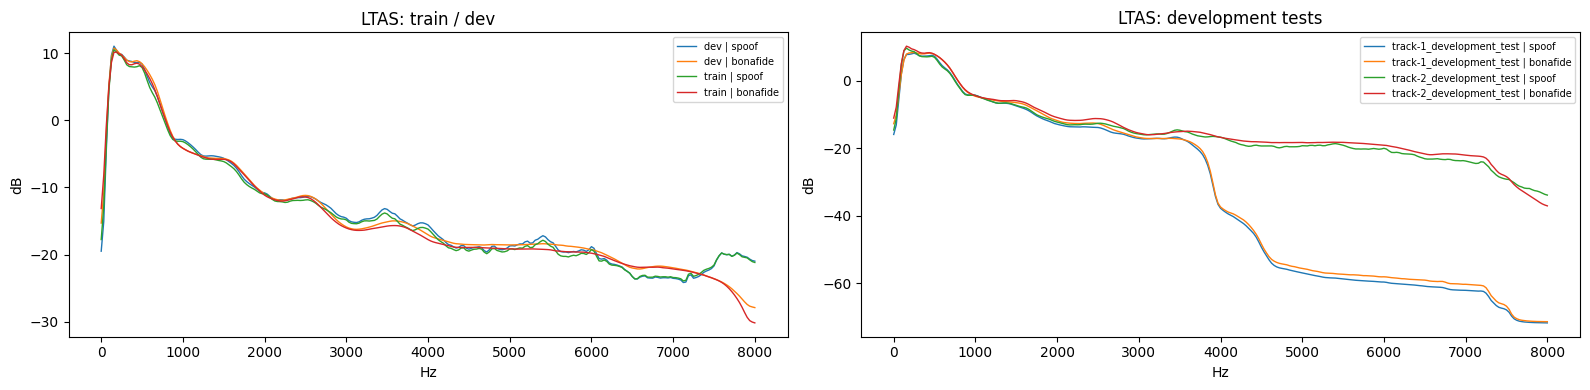

In [11]:
f = np.fft.rfftfreq(512, 1 / 16000)
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
for (s, l), (acc, n) in sorted(LTAS.items(), key=str):
    if n == 0: continue
    a = ax[0] if s in ("train", "dev") else ax[1]
    a.plot(f, 10 * (acc / n), label=f"{s} | {'bonafide' if l == 1 else 'spoof'}", lw=1)
for a, t in zip(ax, ["train / dev", "development tests"]):
    a.set_title(f"LTAS: {t}"); a.set_xlabel("Hz"); a.set_ylabel("dB"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Result:** Train/dev are full band (up to 8 kHz); spoofs have extra energy at 7.5-8 kHz. Track 1 dev-test drops sharply above 4 kHz for both classes (narrowband, telephone-like): a strong channel mismatch with train. Track 2 dev-test is full band.

## 7. Shortcut audit
EER of each single feature used as a detector (50% = no information). Nuisance cues (loudness, silence, duration) under 40% are shortcuts to neutralize; spectral cues may be real TTS artifacts.

In [12]:
rows = []
for s in ["train", "dev", "track-1_development_test", "track-2_development_test"]:
    d = F[F.cfg == s].dropna(subset=["label"])
    if d.label.nunique() < 2: continue
    for c in COLS + ["dur"]:
        e = AD.compute_eer(d.label.astype(int), d[c].fillna(0)); rows.append(dict(split=s, feature=c, EER=round(min(e, 100 - e), 1)))
SHORT = pd.DataFrame(rows).pivot(index="feature", columns="split", values="EER")
print(SHORT.sort_values("train"))
NUISANCE = ["rms_db", "peak", "dc", "clip_frac", "lead_sil", "trail_sil", "speech_ratio", "dur"]
low = SHORT[(SHORT[["train", "dev"]] < 40).any(axis=1)].index.tolist()  # decide on train/dev only; dev-test columns are descriptive
risky = [c for c in low if c in NUISANCE]
print("\nNuisance shortcuts (EER < 40%):", risky or "none")
print("Informative spectral cues (EER < 40%):", [c for c in low if c not in NUISANCE] or "none")

split          dev  track-1_development_test  track-2_development_test  train
feature                                                                      
trail_sil     15.1                      31.7                      38.0   15.0
lead_sil      15.7                      18.1                      29.2   15.2
snr_est       30.4                      28.9                      38.5   31.9
speech_ratio  33.1                      32.7                      36.4   35.7
rms_db        38.7                      37.2                      33.3   41.0
dur           46.2                      47.6                      47.8   45.9
clip_frac     48.1                      49.1                      49.3   47.3
dc            48.9                      46.0                      49.8   48.8
centroid      49.6                      46.7                      48.0   49.4
rolloff95     49.2                      48.0                      48.7   49.5
peak          48.9                      45.7                    

**Result:** Silence is a strong shortcut in train/dev (lead/trail EER ≈15%). The preprocessing decision uses train and dev only; the development-test columns are shown for description and were not used for selection. Duration is not a shortcut (EER ≈46%).

## 8. Data quality issues
Silent, clipped, extreme-duration and duplicate clips (metadata hash across all splits, waveform hash on extracted splits).

In [13]:
PRIORITY = {s: i for i, s in enumerate(SPLITS)}   # duplicates are kept in the higher-priority split (train first)
issues = []
q = F.assign(silent=F.peak < 50 / 32768)
for _, r in q[q.silent].iterrows(): issues.append((r.cfg, r.id, "silent", True))
for _, r in q[q.clip_frac > 0.01].iterrows(): issues.append((r.cfg, r.id, "clipped>1%", False))
for _, r in ALL[ALL.duration_sec > 30].iterrows(): issues.append((r.cfg, r.id, "duration>30s", False))
for _, r in ALL[ALL.duration_sec < 0.5].iterrows(): issues.append((r.cfg, r.id, "duration<0.5s", False))

def dup_drops(df, key, name):
    d = df.assign(prio=df.cfg.map(PRIORITY)).sort_values(["prio", "id"])
    dup = d[d.duplicated(key, keep="first")]
    for _, r in dup.iterrows(): issues.append((r.cfg, r.id, f"duplicate ({name})", True))
    return len(dup)
print("metadata sha256 duplicates dropped:", dup_drops(ALL, "sha256", "sha256"))
print("waveform md5 duplicates dropped   :", dup_drops(F, "wav_md5", "waveform"))
print("trimmed md5 duplicates dropped    :", dup_drops(F, "trim_md5", "trimmed waveform"))

ISS = pd.DataFrame(issues, columns=["cfg", "id", "reason", "drop"]).drop_duplicates(["cfg", "id", "reason"])
print(pd.crosstab(ISS.reason, ISS.cfg))

metadata sha256 duplicates dropped: 10
waveform md5 duplicates dropped   : 0
trimmed md5 duplicates dropped    : 1
cfg                           dev  track-1_development_test  track-1_test  track-2_development_test  track-2_test  train
reason                                                                                                                  
clipped>1%                      0                         0             0                         0             0      1
duplicate (sha256)              0                         0             9                         0             1      0
duplicate (trimmed waveform)    0                         0             0                         0             0      1
duration<0.5s                   0                         0             1                         0             1      0
duration>30s                    0                        77           621                        68           621      1
silent                          2     

**Result:** Problem clips: 20 silent (train 18, all spoof; dev 2), 1 trimmed duplicate in train, and in the tests 10 sha256 duplicates and 1 silent clip. Clips over 30 s are flagged only.

In [14]:
# 8b. Listen to outliers: longest clips (all spoof) and silent clips
from IPython.display import Audio, display
for _, r in F.nlargest(3, "dur").iterrows():
    print(f"{r.cfg} | {r.id} | {r.label_name} | {r.dur:.1f} s (first 20 s)")
    display(Audio(AD.load_wave(f"{AUDIO_ROOT}/{r.cfg}/{r.id}.flac")[:20 * 16000], rate=16000))
for _, r in F[F.peak < 50 / 32768].head(2).iterrows():
    print(f"silent: {r.cfg} | {r.id} | {r.label_name} | {r.dur:.1f} s")
    display(Audio(AD.load_wave(f"{AUDIO_ROOT}/{r.cfg}/{r.id}.flac"), rate=16000))

track-1_development_test | test_0375788 | spoof | 95.0 s (first 20 s)


track-1_development_test | test_0590156 | spoof | 95.0 s (first 20 s)


track-1_development_test | test_0612266 | spoof | 95.0 s (first 20 s)


silent: train | EGY_Male_train_2168765 | spoof | 15.8 s


silent: train | EGY_Male_train_9121147 | spoof | 0.8 s


الـ train: المقطعين الصامتين/المشوشين حذفهم
*   ذي تكرار test_0590156
*   train_2168765 و train_9121147 تشويش و فاضيا
*   test_0375788 ف  غير مفهوم تكرار و فاضي بالنص غريبه

We shouldn’t remove anything from the test set. The baseline and all participating teams were evaluated on the full test set. If we remove even 11 audio samples, our EER will no longer be directly comparable to their results

In [15]:
# 8c. Deep leakage check (part 1): near-duplicates with XLS-R embeddings, train vs dev and dev-tests
# Positive control: train clips passed through a telephone/codec-like channel show what a "leaked" pair looks like.
import torch
from transformers import AutoFeatureExtractor, AutoModel, AutoModelForAudioXVector
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_PER_SPLIT = 5000          # clips per split (raise for more coverage; ~1 min per 1,000 clips on a T4)
WIN = 64600

def sample_split(s, n):
    d = F[(F.cfg == s) & (F.peak >= 50 / 32768)]
    return d.sample(min(n, len(d)), random_state=SEED).reset_index(drop=True)

def embed_waves(waves, model_name, layer=None, xvector=False, bs=16):
    fe = AutoFeatureExtractor.from_pretrained(model_name)
    m = (AutoModelForAudioXVector if xvector else AutoModel).from_pretrained(model_name).to(DEVICE).eval()
    out = []
    for i in range(0, len(waves), bs):
        inp = fe([w for w in waves[i:i + bs]], sampling_rate=16000, return_tensors="pt", padding=True)
        inp = {k: v.to(DEVICE) for k, v in inp.items()}
        with torch.no_grad(), torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            e = m(**inp).embeddings if xvector else m(**inp, output_hidden_states=True).hidden_states[layer].mean(1)
        out.append(torch.nn.functional.normalize(e.float(), dim=-1).cpu())
    del m; torch.cuda.empty_cache()
    return torch.cat(out)

def first_window(r):
    return AD.crop_or_pad(AD.load_wave(f"{AUDIO_ROOT}/{r.cfg}/{r.id}.flac"), WIN, train=False)

SAMP = {s: sample_split(s, N_PER_SPLIT) for s in ["train", "dev", "track-1_development_test", "track-2_development_test"]}
EMB = {s: embed_waves([first_window(r) for _, r in d.iterrows()], "facebook/wav2vec2-xls-r-300m", layer=8) for s, d in SAMP.items()}

ctrl = SAMP["train"].head(500)
rng = np.random.RandomState(SEED)
ctrl_aug = [AD.augment(first_window(r), rng, p=1.0) for _, r in ctrl.iterrows()]
E_ctrl = embed_waves(ctrl_aug, "facebook/wav2vec2-xls-r-300m", layer=8)
pos = (E_ctrl * EMB["train"][:len(ctrl)]).sum(1).numpy()          # same clip, degraded channel
THR = float(np.percentile(pos, 5))
print(f"positive control (same clip, degraded): median {np.median(pos):.4f}, 5th pct {THR:.4f} -> threshold")

LEAK = []
for s in ["dev", "track-1_development_test", "track-2_development_test"]:
    S = EMB[s] @ EMB["train"].T
    nn_sim, nn_idx = S.max(1)
    hit = (nn_sim > THR).numpy()
    print(f"{s}: {hit.mean() * 100:.2f}% of clips have a train clip above threshold | max sim {nn_sim.max():.4f}")
    for j in np.argsort(-nn_sim.numpy())[:5]:
        LEAK.append(dict(split=s, clip=SAMP[s].id[j], clip_label=SAMP[s].label_name[j], train=SAMP["train"].id[int(nn_idx[j])],
                         train_label=SAMP["train"].label_name[int(nn_idx[j])], sim=round(float(nn_sim[j]), 4)))
LEAK = pd.DataFrame(LEAK); print(LEAK)

preprocessor_config.json:   0%|          | 0.00/212 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.57k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.27GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (7 outputs left out)

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


positive control (same clip, degraded): median 0.9408, 5th pct 0.8706 -> threshold
dev: 99.94% of clips have a train clip above threshold | max sim 0.9901
track-1_development_test: 99.96% of clips have a train clip above threshold | max sim 0.9870
track-2_development_test: 99.74% of clips have a train clip above threshold | max sim 0.9892
                       split                  clip clip_label                     train train_label     sim
0                        dev  MSA_Male_dev_3213286      spoof    MSA_Male_train_3484866       spoof  0.9901
1                        dev  MSA_Male_dev_2467183      spoof    MSA_Male_train_8416000       spoof  0.9896
2                        dev  MSA_Male_dev_5913519      spoof    MSA_Male_train_2601964       spoof  0.9893
3                        dev  MSA_Male_dev_2650413      spoof    MSA_Male_train_0433455       spoof  0.9891
4                        dev  MSA_Male_dev_2302321      spoof    MSA_Male_train_4584365       spoof  0.9891
5   track-1

In [16]:
# 8c. Listen to the closest pair (change ROW). Same recording = leakage; same voice/sentence only = not a duplicate.
ROW = 0
r = LEAK.iloc[ROW]; print(r.to_dict())
display(Audio(AD.load_wave(f"{AUDIO_ROOT}/{r['split']}/{r['clip']}.flac"), rate=16000))
display(Audio(AD.load_wave(f"{AUDIO_ROOT}/train/{r['train']}.flac"), rate=16000))

{'split': 'dev', 'clip': 'MSA_Male_dev_3213286', 'clip_label': 'spoof', 'train': 'MSA_Male_train_3484866', 'train_label': 'spoof', 'sim': 0.9901}


**Result:** No copied audio between train and the other splits. Exact checks (waveform md5) found 0 copies; the highest XLS-R similarity is 0.990, and the closest pair (MSA_Male_dev_3213286 / MSA_Male_train_3484866) is the same voice saying different words, not the same recording. The 0.87 threshold was too loose (99.9% pass) because clips share speakers and TTS systems.

نفس الصوت لكن الكلام مختلف

preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/58.6k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  405MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/266 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  404MB            

model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:6829: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(


Loading weights:   0%|          | 0/266 [00:00<?, ?it/s]

calibrated speaker threshold 0.825 (speaker-verification EER on this data 2.6%)


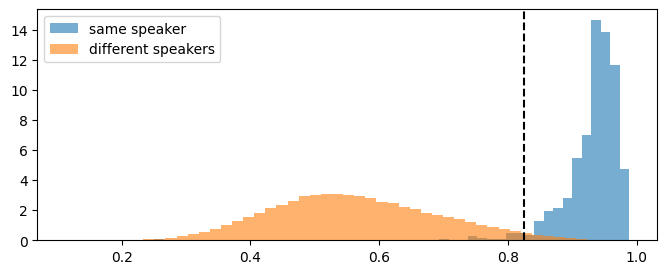

Loading weights:   0%|          | 0/266 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:6829: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(


Loading weights:   0%|          | 0/266 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/266 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/266 [00:00<?, ?it/s]

dev: 99.8% of clips have a same-speaker bona fide clip in train (estimate, 2,000-clip samples)
track-1_development_test: 99.6% of clips have a same-speaker bona fide clip in train (estimate, 2,000-clip samples)
track-2_development_test: 99.7% of clips have a same-speaker bona fide clip in train (estimate, 2,000-clip samples)


In [17]:
# 8d. Deep leakage check (part 2): speaker overlap with a threshold calibrated on this data
# genuine = two halves of the same bona fide clip (same speaker); impostor = male vs female clips (different speakers)
SPK = "microsoft/wavlm-base-plus-sv"
bf = F[(F.cfg == "train") & (F.label == 1) & (F.dur >= 7) & F.gender.isin(["Male", "Female"])]
bf = bf.sample(min(800, len(bf)), random_state=SEED)
w = [AD.load_wave(f"{AUDIO_ROOT}/train/{i}.flac") for i in bf.id]
A = embed_waves([x[:3 * 16000] for x in w], SPK, xvector=True)
B = embed_waves([x[-3 * 16000:] for x in w], SPK, xvector=True)
genuine = (A * B).sum(1).numpy()
g = bf.gender.values
impostor = (A[g == "Male"] @ B[g == "Female"].T).flatten().numpy()
from sklearn.metrics import roc_curve
y = np.r_[np.ones(len(genuine)), np.zeros(len(impostor))]; sc = np.r_[genuine, impostor]
fpr, tpr, th = roc_curve(y, sc); k = np.nanargmin(np.abs(1 - tpr - fpr))
SPK_THR = float(th[k])
print(f"calibrated speaker threshold {SPK_THR:.3f} (speaker-verification EER on this data {100 * (fpr[k] + 1 - tpr[k]) / 2:.1f}%)")
plt.figure(figsize=(8, 3)); plt.hist(genuine, 50, alpha=.6, density=True, label="same speaker")
plt.hist(impostor, 50, alpha=.6, density=True, label="different speakers"); plt.axvline(SPK_THR, c="k", ls="--"); plt.legend(); plt.show()

SPKE = {s: embed_waves([first_window(r)[:3 * 16000] for _, r in d.head(2000).iterrows()], SPK, xvector=True) for s, d in SAMP.items()}
tr_bf = torch.as_tensor(SAMP["train"].head(2000).label.values == 1)
for s in ["dev", "track-1_development_test", "track-2_development_test"]:
    nn = (SPKE[s] @ SPKE["train"][tr_bf].T).max(1).values.numpy()
    print(f"{s}: {100 * (nn > SPK_THR).mean():.1f}% of clips have a same-speaker bona fide clip in train (estimate, 2,000-clip samples)")

**Result:** Speaker threshold 0.825 separates speakers well (EER 2.6%). 99.6-99.8% of dev and dev-test clips have a same-speaker bona fide clip in train (dataset design). Every speaker has real and fake clips, so the speaker does not reveal the label.

## 9. Preprocessing decisions
Train: one random 4.04 s window per clip. Eval: the whole clip in 4.04 s windows, scores averaged. Silence trimming and loudness normalization are on because section 7 found a shortcut.

In [18]:
CONFIG = dict(AD.DEFAULT_CONFIG)
CONFIG["crop_sec"] = 64600 / 16000   # 4.04 s window (official baseline); eval clips are covered fully by consecutive windows
CONFIG["trim_silence"] = any(c in risky for c in ["lead_sil", "trail_sil", "speech_ratio"])
CONFIG["normalize"] = "rms" if any(c in risky for c in ["rms_db", "peak"]) else "none"
CONFIG["augment_p"] = 0.5         # train only; the paper's top teams also used codec, MUSAN noise and RIR augmentation
print(CONFIG)

{'crop_sec': 4.0375, 'trim_silence': True, 'normalize': 'rms', 'augment_p': 0.5}


**Result:** Window 64,600 samples (4.04 s); silence trimming and RMS normalization ON (from section 7); train augmentation p = 0.5.

In [19]:
# 9b. Check the shortcuts are gone after preprocessing (trim silence + RMS normalization)
parts = [d.sample(min(1000, len(d)), random_state=SEED) for _, d in F[F.cfg.isin(["train", "dev"])].groupby(["cfg", "label"])]
chk = pd.concat(parts)
rows = []
for _, r in chk.iterrows():
    x = AD.clean_wave(AD.load_wave(f"{AUDIO_ROOT}/{r.cfg}/{r.id}.flac"), CONFIG)
    d, _ = acoustic_features(np.clip(x * 32767, -32768, 32767).astype(np.int16))
    rows.append(dict(cfg=r.cfg, label=r.label, **d))
P = pd.DataFrame(rows); out = []
for s, d in P.groupby("cfg"):
    for c in ["lead_sil", "trail_sil", "speech_ratio", "rms_db", "snr_est"]:
        e = AD.compute_eer(d.label.astype(int), d[c]); out.append(dict(split=s, feature=c, EER=round(min(e, 100 - e), 1)))
after = pd.DataFrame(out).pivot(index="feature", columns="split", values="EER")
print(pd.concat({"before": SHORT.loc[after.index, ["dev", "train"]], "after": after}, axis=1))

             before       after      
split           dev train   dev train
feature                              
lead_sil       15.7  15.2  49.9  49.9
rms_db         38.7  41.0  49.0  47.9
snr_est        30.4  31.9  40.9  39.5
speech_ratio   33.1  35.7  41.8  41.0
trail_sil      15.1  15.0  49.9  49.8


**Result:** After trimming and RMS normalization the silence and loudness shortcuts are gone (lead/trail EER 15% -> 49.9%, rms_db 41% -> 48%). SNR and speech ratio stay weak (40-42%).

## 10. Clean manifests
One table per split in `MANIFEST[split]` with `id, label, dialect, gender, duration, path, keep, drop_reason`. Official splits are kept as-is.

In [20]:
drop = ISS[ISS["drop"]].groupby(["cfg", "id"])["reason"].apply("; ".join)
CLEAN_SPLITS = ["train", "dev"]   # drop only here; test splits stay complete (official, comparable to the paper)
SUMMARY, MANIFEST = [], {}
for s in SPLITS:
    m = ALL[ALL.cfg == s][["id", "label", "dialect", "gender", "duration_sec", "sha256"]].copy()
    m["split"] = s; m["path"] = s + "/" + m["id"] + ".flac"
    m["drop_reason"] = [drop.get((s, i), "") for i in m.id]
    m["flag"] = m["drop_reason"] != ""
    m["keep"] = ~m["flag"] if s in CLEAN_SPLITS else True
    m["extracted"] = s in EXTRACT_SPLITS
    MANIFEST[s] = m
    SUMMARY.append(dict(split=s, rows=len(m), flagged=int(m.flag.sum()), dropped=int((~m.keep).sum()), kept=int(m.keep.sum()),
                        bonafide=int(m[m.keep].label.sum()), spoof=int((m[m.keep].label == 0).sum())))
print(pd.DataFrame(SUMMARY))
print("class weights [spoof, bonafide]:", AD.class_weights(MANIFEST["train"]))

                      split    rows  flagged  dropped    kept  bonafide   spoof
0                     train   22500       18       18   22482      7500   14982
1                       dev   21000        2        2   20998      6952   14046
2  track-1_development_test   16023        1        0   16023      4097   11926
3  track-2_development_test   14193        0        0   14193      3510   10683
4              track-1_test  144210        9        0  144210     36903  107307
5              track-2_test  127746        1        0  127746     31490   96256
class weights [spoof, bonafide]: [0.750300360432519, 1.4988]


**Result:** Clean train 22,482 and dev 20,998 clips; test splits kept complete (problem clips flagged, not dropped). Class weights [spoof 0.75, bona fide 1.50].

In [21]:
# 10b. Save the clean manifests, flagged issues and preprocessing settings (read by the training code in section 12)
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/nabra/artifacts/aradf_eda"   # team Drive folder
else:
    OUT_DIR = "artifacts/aradf_eda"
os.makedirs(f"{OUT_DIR}/manifests", exist_ok=True)

for s, m in MANIFEST.items():
    m.to_csv(f"{OUT_DIR}/manifests/{s}.csv", index=False)
ISS.to_csv(f"{OUT_DIR}/data_issues.csv", index=False)
SHORT.to_csv(f"{OUT_DIR}/shortcut_audit.csv")
pd.DataFrame(SUMMARY).to_csv(f"{OUT_DIR}/manifest_summary.csv", index=False)

with open(f"{OUT_DIR}/preprocessing_config.json", "w", encoding="utf-8") as f:
    json.dump({
        "dataset": REPO_ID,
        "revision": REVISION,
        "audio_root": AUDIO_ROOT,
        "labels": {"1": "bona fide (real)", "0": "spoof (fake)"},
        "score_direction": "higher score = more bona fide",
        "clean_splits": CLEAN_SPLITS,
        "config": CONFIG,
    }, f, indent=2)

print("Saved to", OUT_DIR)
print("Manifests:", sorted(os.listdir(f"{OUT_DIR}/manifests")))

Mounted at /content/drive
Saved to /content/drive/MyDrive/nabra/artifacts/aradf_eda
Manifests: ['dev.csv', 'track-1_development_test.csv', 'track-1_test.csv', 'track-2_development_test.csv', 'track-2_test.csv', 'train.csv']


## 11. Pipeline sanity check
Load a training batch, check shapes and labels, and compare one clip before and after preprocessing.

train batch: (16, 64600) torch.float32 | labels: [0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0]
real share over 30 balanced batches: 0.47 (expected ~0.50)
train / dev size: 22482 20998
eval batch: (12, 64600) | windows per clip: [3, 3, 3, 3] | durations: [10.1, 8.8, 8.3, 12.3]


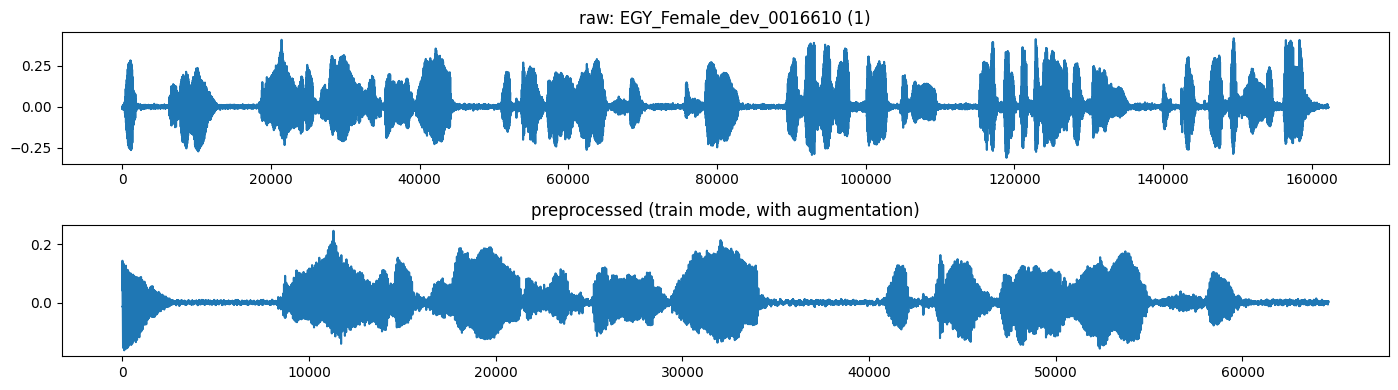

In [22]:
import torch
ds_tr = AD.make_dataset(MANIFEST["train"], AUDIO_ROOT, CONFIG, train=True)
ds_dv = AD.make_dataset(MANIFEST["dev"], AUDIO_ROOT, CONFIG, train=False)
dl = AD.make_loader(ds_tr, batch_size=16, train=True, balanced=True, num_workers=0)
xb, yb, ib = next(iter(dl))
print("train batch:", tuple(xb.shape), xb.dtype, "| labels:", yb.tolist())
share = np.mean([next(iter(dl))[1].float().mean().item() for _ in range(30)])
print(f"real share over 30 balanced batches: {share:.2f} (expected ~0.50)")
print("train / dev size:", len(ds_tr), len(ds_dv))

dv_dl = AD.make_loader(ds_dv, batch_size=4, train=False)
wb, lb, idb, cnt = next(iter(dv_dl))
print("eval batch:", tuple(wb.shape), "| windows per clip:", cnt, "| durations:",
      [round(float(d), 1) for d in ds_dv.df.duration_sec[:4]])

from IPython.display import Audio, display
r = ds_dv.df.iloc[0]; raw = AD.load_wave(os.path.join(AUDIO_ROOT, r.path))
proc = AD.preprocess(raw, {**CONFIG, "augment_p": 0.9}, train=True)
fig, ax = plt.subplots(2, 1, figsize=(14, 4)); ax[0].plot(raw); ax[0].set_title(f"raw: {r.id} ({r.label})")
ax[1].plot(proc); ax[1].set_title("preprocessed (train mode, with augmentation)"); plt.tight_layout(); plt.show()
display(Audio(raw, rate=16000)); display(Audio(proc, rate=16000))

**Result:** Train batch [16, 64600]; balanced sampler gives 0.50 real. Eval covers the whole clip (8-12 s clips -> 3 windows each).

In [23]:
print(pd.DataFrame(SUMMARY).to_string(index=False))
print("\npreprocessing config:", CONFIG)
print("dropped clips by reason:"); print(ISS[ISS["drop"]].groupby(["reason", "cfg"]).size().unstack(fill_value=0))

                   split   rows  flagged  dropped   kept  bonafide  spoof
                   train  22500       18       18  22482      7500  14982
                     dev  21000        2        2  20998      6952  14046
track-1_development_test  16023        1        0  16023      4097  11926
track-2_development_test  14193        0        0  14193      3510  10683
            track-1_test 144210        9        0 144210     36903 107307
            track-2_test 127746        1        0 127746     31490  96256

preprocessing config: {'crop_sec': 4.0375, 'trim_silence': True, 'normalize': 'rms', 'augment_p': 0.5}
dropped clips by reason:
cfg                           dev  track-1_development_test  track-1_test  track-2_test  train
reason                                                                                        
duplicate (sha256)              0                         0             9             1      0
duplicate (trimmed waveform)    0                         0         

**Result:** Final clean data and preprocessing settings, ready for model training.

## 12. Full fine-tuning (Part B)
Two runs with the same code: `MODEL = "xlsr300m"` then `MODEL = "wavlm_large"` (cell 12.2). Everything else stays fixed.

**How to run (Colab)**
1. Runtime → Change runtime type → **L4 GPU**.
2. Google Drive must contain `MyDrive/nabra/artifacts/aradf_eda` (from section 10b, or the shared folder added to *My Drive*). Free Drive space needed: about 7 GB.
3. Run the cells of section 12 in order, starting at 12.1. Part A does not need to be run again.
4. If the session disconnects, run section 12 again from 12.1: training continues from the last finished epoch.
5. Keep the browser tab open while training. After 12.9 finishes: Runtime → Disconnect and delete runtime.

Optional first check: set `QUICK_TEST = True` in 12.2 (64 clips, 1 epoch, a few minutes), then set it back to `False`.

| Setting | Value | Source |
|---|---|---|
| Trainable | all weights (SSL encoder + AASIST) | official baseline |
| Optimizer | Adam, lr 1e-6, weight decay 1e-4 | official `config.yaml` |
| Scheduler | exponential, gamma 0.9 per epoch | official `config.yaml` |
| Batch | 32 | official `config.yaml` |
| Epochs | max 20, early stopping patience 5 on dev EER | team decision (official: 100 / 7) |
| Loss | cross-entropy, class weights [0.3 spoof, 0.7 bona fide] | official `config.yaml` |
| Back end | AASIST + Linear(160→2) | DeepFense (official baseline code) |
| Input | 64,600 samples (4.04 s), repeat padding, random crop in training | official `config.yaml` |
| Preprocessing | silence trimming + RMS normalization (−23 dBFS) | EDA section 9 |
| Augmentation | none | official baseline |
| Score | logit(bona fide) − logit(spoof) | Raid AI, pi-labs, UZH-CL |
| Dev EER during training | one centre 4.04 s crop | UZH-CL |
| Final scores | whole clip (consecutive 4.04 s windows), mean score | EDA section 3 |
| Precision | bf16 autocast | Raid AI |

In [11]:
# 12.1 Environment: packages, GPU and Google Drive
import sys, os, json, time, math, platform, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers==5.18.0",
                    "huggingface-hub==1.33.0", "codecarbon==3.3.2", "soundfile"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")

import numpy as np, pandas as pd, torch, transformers, huggingface_hub
assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > L4"
if transformers.__version__ != "5.18.0":
    print("WARNING: transformers", transformers.__version__, "is loaded. Restart the session (Runtime > Restart session) and run 12.1 again.")
GPU_NAME = torch.cuda.get_device_name(0)
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 2**30
print("Python", platform.python_version(), "| torch", torch.__version__, "| transformers", transformers.__version__,
      "| huggingface_hub", huggingface_hub.__version__)
print(f"GPU: {GPU_NAME} | {GPU_GB:.1f} GB | bf16: {torch.cuda.is_bf16_supported()}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Python 3.13.16 | torch 2.14.1+cu130 | transformers 5.18.0 | huggingface_hub 1.33.0
GPU: NVIDIA L4 | 22.0 GB | bf16: True


In [12]:
# 12.2 Settings: change only MODEL (and QUICK_TEST for a short trial run)
MODEL = "xlsr300m"        # "xlsr300m" or "wavlm_large"
QUICK_TEST = False        # True = 64 train / 64 dev clips, 1 epoch, dev only (checks the whole pipeline)

HF_MODELS = {"xlsr300m": "facebook/wav2vec2-xls-r-300m", "wavlm_large": "microsoft/wavlm-large"}
REPO_ID = "ArabicSpeech/ArA-DF-2026"
REVISION = "2b1f042dc166b1d372841cb0d7110661ea5b2a93"      # pinned dataset version (same as Part A)

if IN_COLAB:
    PROJECT_ROOT = "/content/drive/MyDrive/nabra"          # team Drive folder
    AUDIO_ROOT = "/content/aradf_audio"                    # Colab local disk (fast); extracted again in each session
else:
    PROJECT_ROOT = r"C:\Users\Aisha\OneDrive\سطح المكتب\vss\Grad"
    AUDIO_ROOT = r"C:\Users\Aisha\nabra_data\aradf_audio"
ART_DIR = os.path.join(PROJECT_ROOT, "artifacts", "aradf_eda")    # clean manifests from section 10b
RUN_DIR = os.path.join(PROJECT_ROOT, "runs", f"{MODEL}__fullft" + ("__quicktest" if QUICK_TEST else ""))

CFG = dict(
    method="full_finetuning", model=MODEL, hf_model=HF_MODELS[MODEL], dataset=REPO_ID, revision=REVISION,
    seed=42,                                     # official config.yaml
    sample_rate=16000, max_len=64600,            # official config.yaml: pad max_len 64600, repeat padding
    trim_silence=True, rms_dbfs=-23.0,           # EDA section 9 (removes the silence / loudness shortcut)
    augmentation=None,                           # official baseline: no augmentation
    trainable="all",                             # full fine-tuning: SSL encoder + AASIST
    optimizer="adam", lr=1e-6, weight_decay=1e-4,   # official config.yaml
    scheduler="exponential", gamma=0.9,          # official config.yaml, stepped once per epoch
    batch_size=32,                               # official config.yaml
    max_epochs=20, patience=5,                   # team decision (official: 100 epochs, patience 7)
    monitor="dev EER, min",                      # official config.yaml: monitor_metric EER, mode min
    class_weights=[0.3, 0.7],                    # official config.yaml, order [spoof, bona fide]
    aasist=dict(filts=[70, [1, 32], [32, 32], [32, 64], [64, 64]], gat_dims=[64, 32],
                pool_ratios=[0.5, 0.7, 0.5, 0.5], temperatures=[2.0, 2.0, 100.0, 100.0]),   # DeepFense defaults
    score="logit_bonafide - logit_spoof",        # Raid AI, pi-labs, UZH-CL
    dev_eval_in_training="one centre crop of 64,600 samples",            # UZH-CL
    final_eval="whole clip, consecutive 64,600-sample windows, mean score",   # EDA section 3 (make_windows)
    precision="bf16 autocast",                   # Raid AI; needed for memory and speed
    gradient_checkpointing=True,                 # memory only; gradients are the same
    spec_augment=False,                          # official front end runs with mask=False
)
if QUICK_TEST:
    CFG["max_epochs"] = 1
EVAL_SPLITS = ["dev"] if QUICK_TEST else ["dev", "track-1_test"]
os.makedirs(RUN_DIR, exist_ok=True)

import random
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = False
set_seed(CFG["seed"])
print("model:", CFG["hf_model"], "| run folder:", RUN_DIR)

model: facebook/wav2vec2-xls-r-300m | run folder: /content/drive/MyDrive/nabra/runs/xlsr300m__fullft


In [13]:
# 12.3 Data: clean manifests (section 10b) and audio for train / dev
import tarfile
from huggingface_hub import HfApi, hf_hub_download
HF_TOKEN = os.environ.get("HF_TOKEN")    # optional: the dataset is public

assert os.path.isdir(os.path.join(ART_DIR, "manifests")), f"No manifests in {ART_DIR}. Run section 10b or add the shared folder to My Drive."
with open(os.path.join(ART_DIR, "preprocessing_config.json"), encoding="utf-8") as f:
    PREP = json.load(f)
assert PREP["revision"] == REVISION, "Manifests were made from a different dataset version"

def load_manifest(split):
    m = pd.read_csv(os.path.join(ART_DIR, "manifests", f"{split}.csv"))
    return m[m["keep"].astype(bool)].reset_index(drop=True)

MAN = {s: load_manifest(s) for s in ["train", "dev", "track-1_test"]}
for s, m in MAN.items():
    print(f"{s:13s} {len(m):7,d} clips | bona fide {int(m.label.sum()):6,d} | spoof {int((m.label == 0).sum()):7,d}")
assert (len(MAN["train"]), len(MAN["dev"]), len(MAN["track-1_test"])) == (22482, 20998, 144210)
if QUICK_TEST:
    for s in ["train", "dev"]:
        MAN[s] = MAN[s].sample(64, random_state=CFG["seed"]).reset_index(drop=True)

def extract_split(split, ids):
    """Download the split's tar shards (pinned revision) and write AUDIO_ROOT/<split>/<id>.flac for the given ids."""
    os.makedirs(os.path.join(AUDIO_ROOT, split), exist_ok=True)
    want = {i for i in ids if not os.path.exists(os.path.join(AUDIO_ROOT, split, f"{i}.flac"))}
    if not want:
        print(f"{split}: all {len(ids):,} clips already on disk"); return
    files = HfApi().list_repo_files(REPO_ID, repo_type="dataset", revision=REVISION, token=HF_TOKEN)
    tars = sorted(f for f in files if f.startswith(f"data/{split}/") and f.endswith(".tar"))
    t0 = time.time()
    for t in tars:
        local = hf_hub_download(REPO_ID, t, repo_type="dataset", revision=REVISION, token=HF_TOKEN)
        with tarfile.open(local) as tf:
            for mem in tf:
                if mem.isfile() and mem.name.endswith(".flac"):
                    cid = os.path.basename(mem.name)[:-5]
                    if cid in want:
                        with open(os.path.join(AUDIO_ROOT, split, f"{cid}.flac"), "wb") as f:
                            f.write(tf.extractfile(mem).read())
        print(f"  {t} | {time.time() - t0:.0f}s")
    missing = [i for i in ids if not os.path.exists(os.path.join(AUDIO_ROOT, split, f"{i}.flac"))]
    assert not missing, f"{split}: {len(missing)} clips missing after extraction"
    print(f"{split}: {len(ids):,} clips ready")

for s in ["train", "dev"]:
    extract_split(s, MAN[s]["id"].tolist())

train          22,482 clips | bona fide  7,500 | spoof  14,982
dev            20,998 clips | bona fide  6,952 | spoof  14,046
track-1_test  144,210 clips | bona fide 36,903 | spoof 107,307
train: all 22,482 clips already on disk
dev: all 20,998 clips already on disk


In [14]:
# 12.4 Preprocessing and data loaders (section 3 functions; changes for training are marked CHANGE)
import soundfile as sf
SR, N = CFG["sample_rate"], CFG["max_len"]

def load_wave(path):
    x, sr = sf.read(path, dtype="float32", always_2d=False)
    if x.ndim > 1: x = x.mean(1)
    assert sr == SR, f"{path}: sr={sr}"
    return x

def trim_silence(x, top_db=40.0, frame=400, hop=160):
    """Remove leading/trailing frames quieter than (max frame energy - top_db)."""
    if len(x) < frame: return x
    nf = 1 + (len(x) - frame) // hop
    idx = np.arange(frame)[None, :] + hop * np.arange(nf)[:, None]
    e = 10 * np.log10((x[idx] ** 2).mean(1) + 1e-10)
    v = np.flatnonzero(e > e.max() - top_db)
    return x[v[0] * hop: v[-1] * hop + frame] if len(v) else x

def rms_normalize(x, target_dbfs=-23.0):
    rms = np.sqrt(np.mean(x ** 2) + 1e-12)
    return np.clip(x * (10 ** (target_dbfs / 20) / rms), -1, 1).astype(np.float32)

def clean_wave(x):
    if CFG["trim_silence"]: x = trim_silence(x)
    return rms_normalize(x, CFG["rms_dbfs"])

def crop_or_pad(x, n, mode, rng=None):
    """Fixed length n; short clips are repeat-padded. mode: 'random' (train), 'center' (dev during training), 'start'.
    CHANGE: 'center' added; section 3 used the start of the clip for evaluation crops."""
    if len(x) == 0: return np.zeros(n, np.float32)
    if len(x) < n: x = np.tile(x, int(np.ceil(n / len(x))))
    if len(x) == n: return x
    if mode == "random": start = rng.randint(0, len(x) - n + 1)
    elif mode == "center": start = (len(x) - n) // 2
    else: start = 0
    return x[start:start + n]

def make_windows(x, n):
    """Cover the WHOLE clip with windows of n samples (final evaluation). Last window is aligned to the clip end."""
    if len(x) <= n: return crop_or_pad(x, n, "start")[None, :]
    starts = list(range(0, len(x) - n + 1, n))
    if starts[-1] + n < len(x): starts.append(len(x) - n)
    return np.stack([x[s:s + n] for s in starts])

class AraDF(torch.utils.data.Dataset):
    """mode 'random': one random window per clip (train); 'center': one centre window; 'windows': all windows.
    CHANGE: no augmentation (official baseline) and no balanced sampler (class weights in the loss instead)."""
    def __init__(self, manifest, mode):
        self.ids = manifest["id"].tolist(); self.labels = manifest["label"].astype(int).tolist()
        self.paths = manifest["path"].tolist(); self.mode = mode
        self.rng = np.random.RandomState(CFG["seed"])
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        x = clean_wave(load_wave(os.path.join(AUDIO_ROOT, self.paths[i])))
        w = make_windows(x, N) if self.mode == "windows" else crop_or_pad(x, N, self.mode, self.rng)[None, :]
        return torch.from_numpy(np.ascontiguousarray(w, dtype=np.float32)), self.labels[i], self.ids[i]

def seed_worker(worker_id):
    """CHANGE: each DataLoader worker gets its own random generator, derived from the loader seed (reproducible crops)."""
    info = torch.utils.data.get_worker_info()
    info.dataset.rng = np.random.RandomState(torch.initial_seed() % 2**32)

def collate(batch):
    """Stack all windows of all clips; counts tells which windows belong to which clip."""
    waves = torch.cat([b[0] for b in batch])
    return waves, torch.tensor([b[1] for b in batch]), [b[2] for b in batch], [b[0].shape[0] for b in batch]

NUM_WORKERS = min(8, os.cpu_count() or 1) if IN_COLAB else 0    # Windows notebooks: 0
def make_loader(ds, batch_size, shuffle, epoch=0):
    g = torch.Generator(); g.manual_seed(CFG["seed"] + epoch)
    if NUM_WORKERS == 0: ds.rng = np.random.RandomState(CFG["seed"] + epoch)
    return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=shuffle, drop_last=shuffle,
                                       num_workers=NUM_WORKERS, worker_init_fn=seed_worker if NUM_WORKERS else None,
                                       generator=g, collate_fn=collate, pin_memory=True)

ds_train, ds_dev = AraDF(MAN["train"], "random"), AraDF(MAN["dev"], "center")
xb, yb, _, _ = next(iter(make_loader(ds_train, CFG["batch_size"], shuffle=True)))
print("train batch:", tuple(xb.shape), "| bona fide share:", round(float(yb.float().mean()), 2))
xd, yd, _, cd = next(iter(make_loader(ds_dev, 8, shuffle=False)))
print("dev batch (centre crop):", tuple(xd.shape), "| windows per clip:", cd)
xw, _, _, cw = next(iter(make_loader(AraDF(MAN["dev"], "windows"), 4, shuffle=False)))
print("final-eval batch (whole clip):", tuple(xw.shape), "| windows per clip:", cw)
del xb, yb, xd, yd, xw

train batch: (32, 64600) | bona fide share: 0.28
dev batch (centre crop): (8, 64600) | windows per clip: [1, 1, 1, 1, 1, 1, 1, 1]
final-eval batch (whole clip): (12, 64600) | windows per clip: [3, 3, 3, 3]


In [15]:
# 12.5 AASIST back end. Adapted from DeepFense (Apache License 2.0):
#   https://github.com/Yaselley/deepfense-framework  deepfense/models/backends/aasist.py
# Change: no DeepFense registry / BaseBackend; layers and computations are unchanged.
import random
from typing import Union
import torch.nn as nn
import torch.nn.functional as F
from torch import Tensor

class GraphAttentionLayer(nn.Module):
    def __init__(self, in_dim, out_dim, **kwargs):
        super().__init__()

        self.att_proj = nn.Linear(in_dim, out_dim)
        self.att_weight = self._init_new_params(out_dim, 1)

        self.proj_with_att = nn.Linear(in_dim, out_dim)
        self.proj_without_att = nn.Linear(in_dim, out_dim)

        self.bn = nn.BatchNorm1d(out_dim)

        self.input_drop = nn.Dropout(p=0.2)

        self.act = nn.SELU(inplace=True)

        self.temp = 1.0
        if "temperature" in kwargs:
            self.temp = kwargs["temperature"]

    def forward(self, x):
        """
        x   :(#bs, #node, #dim)
        """
        x = self.input_drop(x)

        att_map = self._derive_att_map(x)

        x = self._project(x, att_map)

        x = self._apply_BN(x)
        x = self.act(x)
        return x

    def _pairwise_mul_nodes(self, x):
        """
        Calculates pairwise multiplication of nodes.
        - for attention map
        x           :(#bs, #node, #dim)
        out_shape   :(#bs, #node, #node, #dim)
        """

        nb_nodes = x.size(1)
        x = x.unsqueeze(2).expand(-1, -1, nb_nodes, -1)
        x_mirror = x.transpose(1, 2)

        return x * x_mirror

    def _derive_att_map(self, x):
        """
        x           :(#bs, #node, #dim)
        out_shape   :(#bs, #node, #node, 1)
        """
        att_map = self._pairwise_mul_nodes(x)
        # size: (#bs, #node, #node, #dim_out)
        att_map = torch.tanh(self.att_proj(att_map))
        # size: (#bs, #node, #node, 1)
        att_map = torch.matmul(att_map, self.att_weight)

        att_map = att_map / self.temp

        att_map = F.softmax(att_map, dim=-2)

        return att_map

    def _project(self, x, att_map):
        x1 = self.proj_with_att(torch.matmul(att_map.squeeze(-1), x))
        x2 = self.proj_without_att(x)

        return x1 + x2

    def _apply_BN(self, x):
        org_size = x.size()
        x = x.view(-1, org_size[-1])
        x = self.bn(x)
        x = x.view(org_size)

        return x

    def _init_new_params(self, *size):
        out = nn.Parameter(torch.FloatTensor(*size))
        nn.init.xavier_normal_(out)
        return out


class HtrgGraphAttentionLayer(nn.Module):
    def __init__(self, in_dim, out_dim, **kwargs):
        super().__init__()

        self.proj_type1 = nn.Linear(in_dim, in_dim)
        self.proj_type2 = nn.Linear(in_dim, in_dim)

        # attention map
        self.att_proj = nn.Linear(in_dim, out_dim)
        self.att_projM = nn.Linear(in_dim, out_dim)

        self.att_weight11 = self._init_new_params(out_dim, 1)
        self.att_weight22 = self._init_new_params(out_dim, 1)
        self.att_weight12 = self._init_new_params(out_dim, 1)
        self.att_weightM = self._init_new_params(out_dim, 1)

        # project
        self.proj_with_att = nn.Linear(in_dim, out_dim)
        self.proj_without_att = nn.Linear(in_dim, out_dim)

        self.proj_with_attM = nn.Linear(in_dim, out_dim)
        self.proj_without_attM = nn.Linear(in_dim, out_dim)

        # batch norm
        self.bn = nn.BatchNorm1d(out_dim)

        # dropout for inputs
        self.input_drop = nn.Dropout(p=0.2)

        # activate
        self.act = nn.SELU(inplace=True)

        self.temp = 1.0
        if "temperature" in kwargs:
            self.temp = kwargs["temperature"]

    def forward(self, x1, x2, master=None):
        """
        x1  :(#bs, #node, #dim)
        x2  :(#bs, #node, #dim)
        """
        num_type1 = x1.size(1)
        num_type2 = x2.size(1)

        x1 = self.proj_type1(x1)
        x2 = self.proj_type2(x2)

        x = torch.cat([x1, x2], dim=1)

        if master is None:
            master = torch.mean(x, dim=1, keepdim=True)

        x = self.input_drop(x)

        att_map = self._derive_att_map(x, num_type1, num_type2)

        master = self._update_master(x, master)

        x = self._project(x, att_map)

        x = self._apply_BN(x)
        x = self.act(x)

        x1 = x.narrow(1, 0, num_type1)
        x2 = x.narrow(1, num_type1, num_type2)

        return x1, x2, master

    def _update_master(self, x, master):
        att_map = self._derive_att_map_master(x, master)
        master = self._project_master(x, master, att_map)

        return master

    def _pairwise_mul_nodes(self, x):
        """
        Calculates pairwise multiplication of nodes.
        - for attention map
        x           :(#bs, #node, #dim)
        out_shape   :(#bs, #node, #node, #dim)
        """

        nb_nodes = x.size(1)
        x = x.unsqueeze(2).expand(-1, -1, nb_nodes, -1)
        x_mirror = x.transpose(1, 2)

        return x * x_mirror

    def _derive_att_map_master(self, x, master):
        """
        x           :(#bs, #node, #dim)
        out_shape   :(#bs, #node, #node, 1)
        """
        att_map = x * master
        att_map = torch.tanh(self.att_projM(att_map))

        att_map = torch.matmul(att_map, self.att_weightM)

        att_map = att_map / self.temp

        att_map = F.softmax(att_map, dim=-2)

        return att_map

    def _derive_att_map(self, x, num_type1, num_type2):
        """
        x           :(#bs, #node, #dim)
        out_shape   :(#bs, #node, #node, 1)
        """
        att_map = self._pairwise_mul_nodes(x)
        # size: (#bs, #node, #node, #dim_out)
        att_map = torch.tanh(self.att_proj(att_map))
        # size: (#bs, #node, #node, 1)

        att_board = torch.zeros_like(att_map[:, :, :, 0]).unsqueeze(-1)

        att_board[:, :num_type1, :num_type1, :] = torch.matmul(
            att_map[:, :num_type1, :num_type1, :], self.att_weight11
        )
        att_board[:, num_type1:, num_type1:, :] = torch.matmul(
            att_map[:, num_type1:, num_type1:, :], self.att_weight22
        )
        att_board[:, :num_type1, num_type1:, :] = torch.matmul(
            att_map[:, :num_type1, num_type1:, :], self.att_weight12
        )
        att_board[:, num_type1:, :num_type1, :] = torch.matmul(
            att_map[:, num_type1:, :num_type1, :], self.att_weight12
        )

        att_map = att_board

        att_map = att_map / self.temp


        att_map = F.softmax(att_map, dim=-2)

        return att_map

    def _project(self, x, att_map):
        x1 = self.proj_with_att(torch.matmul(att_map.squeeze(-1), x))
        x2 = self.proj_without_att(x)

        return x1 + x2

    def _project_master(self, x, master, att_map):
        x1 = self.proj_with_attM(torch.matmul(att_map.squeeze(-1).unsqueeze(1), x))
        x2 = self.proj_without_attM(master)

        return x1 + x2

    def _apply_BN(self, x):
        org_size = x.size()
        x = x.view(-1, org_size[-1])
        x = self.bn(x)
        x = x.view(org_size)

        return x

    def _init_new_params(self, *size):
        out = nn.Parameter(torch.FloatTensor(*size))
        nn.init.xavier_normal_(out)
        return out


class GraphPool(nn.Module):
    def __init__(self, k: float, in_dim: int, p: Union[float, int]):
        super().__init__()
        self.k = k
        self.sigmoid = nn.Sigmoid()
        self.proj = nn.Linear(in_dim, 1)
        self.drop = nn.Dropout(p=p) if p > 0 else nn.Identity()
        self.in_dim = in_dim

    def forward(self, h):
        Z = self.drop(h)
        weights = self.proj(Z)
        scores = self.sigmoid(weights)
        new_h = self.top_k_graph(scores, h, self.k)

        return new_h

    def top_k_graph(self, scores, h, k):
        """
        args
        =====
        scores: attention-based weights (#bs, #node, 1)
        h: graph data (#bs, #node, #dim)
        k: ratio of remaining nodes, (float)

        returns
        =====
        h: graph pool applied data (#bs, #node', #dim)
        """
        _, n_nodes, n_feat = h.size()
        n_nodes = max(int(n_nodes * k), 1)
        _, idx = torch.topk(scores, n_nodes, dim=1)
        idx = idx.expand(-1, -1, n_feat)

        h = h * scores
        h = torch.gather(h, 1, idx)

        return h


class Residual_block(nn.Module):
    def __init__(self, nb_filts, pool=(1, 3), first=False):
        super().__init__()
        self.first = first

        if not self.first:
            self.bn1 = nn.BatchNorm2d(num_features=nb_filts[0])
        self.conv1 = nn.Conv2d(
            in_channels=nb_filts[0],
            out_channels=nb_filts[1],
            kernel_size=(2, 3),
            padding=(1, 1),
            stride=1,
        )
        self.selu = nn.SELU(inplace=True)

        self.bn2 = nn.BatchNorm2d(num_features=nb_filts[1])
        self.conv2 = nn.Conv2d(
            in_channels=nb_filts[1],
            out_channels=nb_filts[1],
            kernel_size=(2, 3),
            padding=(0, 1),
            stride=1,
        )

        if nb_filts[0] != nb_filts[1]:
            self.downsample = True
            self.conv_downsample = nn.Conv2d(
                in_channels=nb_filts[0],
                out_channels=nb_filts[1],
                padding=(0, 1),
                kernel_size=(1, 3),
                stride=1,
            )

        else:
            self.downsample = False
        self.mp = nn.MaxPool2d(pool)


    def forward(self, x):
        identity = x
        if not self.first:
            out = self.bn1(x)
            out = self.selu(out)
        else:
            out = x
        out = self.conv1(x)
        out = self.bn2(out)
        out = self.selu(out)
        out = self.conv2(out)

        if self.downsample:
            identity = self.conv_downsample(identity)

        out += identity
        return out


class AASIST(nn.Module):
    # Same layers and defaults as DeepFense AASIST; config dict replaced by keyword arguments.
    def __init__(self, input_dim=1024, filts=(70, [1, 32], [32, 32], [32, 64], [64, 64]), gat_dims=(64, 32),
                 pool_ratios=(0.5, 0.7, 0.5, 0.5), temperatures=(2.0, 2.0, 100.0, 100.0)):
        super().__init__()
        self.LL = nn.Linear(input_dim, 128)

        self.first_bn = nn.BatchNorm2d(num_features=1)
        self.first_bn1 = nn.BatchNorm2d(num_features=64)
        self.drop = nn.Dropout(0.5, inplace=True)
        self.drop_way = nn.Dropout(0.2, inplace=True)
        self.selu = nn.SELU(inplace=True)

        # RawNet2 encoder
        self.encoder = nn.Sequential(
            nn.Sequential(Residual_block(nb_filts=filts[1], first=True)),
            nn.Sequential(Residual_block(nb_filts=filts[2])),
            nn.Sequential(Residual_block(nb_filts=filts[3])),
            nn.Sequential(Residual_block(nb_filts=filts[4])),
            nn.Sequential(Residual_block(nb_filts=filts[4])),
            nn.Sequential(Residual_block(nb_filts=filts[4])),
        )

        self.attention = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=(1, 1)),
            nn.SELU(inplace=True),
            nn.BatchNorm2d(128),
            nn.Conv2d(128, 64, kernel_size=(1, 1)),
        )
        self.pos_S = nn.Parameter(torch.randn(1, 42, filts[-1][-1]))

        self.master1 = nn.Parameter(torch.randn(1, 1, gat_dims[0]))
        self.master2 = nn.Parameter(torch.randn(1, 1, gat_dims[0]))

        # Graph module
        self.GAT_layer_S = GraphAttentionLayer(
            filts[-1][-1], gat_dims[0], temperature=temperatures[0]
        )
        self.GAT_layer_T = GraphAttentionLayer(
            filts[-1][-1], gat_dims[0], temperature=temperatures[1]
        )
        # HS-GAL layer
        self.HtrgGAT_layer_ST11 = HtrgGraphAttentionLayer(
            gat_dims[0], gat_dims[1], temperature=temperatures[2]
        )
        self.HtrgGAT_layer_ST12 = HtrgGraphAttentionLayer(
            gat_dims[1], gat_dims[1], temperature=temperatures[2]
        )
        self.HtrgGAT_layer_ST21 = HtrgGraphAttentionLayer(
            gat_dims[0], gat_dims[1], temperature=temperatures[2]
        )
        self.HtrgGAT_layer_ST22 = HtrgGraphAttentionLayer(
            gat_dims[1], gat_dims[1], temperature=temperatures[2]
        )

        self.pool_S = GraphPool(pool_ratios[0], gat_dims[0], 0.3)
        self.pool_T = GraphPool(pool_ratios[1], gat_dims[0], 0.3)
        self.pool_hS1 = GraphPool(pool_ratios[2], gat_dims[1], 0.3)
        self.pool_hT1 = GraphPool(pool_ratios[2], gat_dims[1], 0.3)

        self.pool_hS2 = GraphPool(pool_ratios[2], gat_dims[1], 0.3)
        self.pool_hT2 = GraphPool(pool_ratios[2], gat_dims[1], 0.3)

    def forward(self, x):
        x = self.LL(x)
        x = x.transpose(1, 2)  # (bs,feat_out_dim,frame_number)
        x = x.unsqueeze(dim=1)  # add channel
        x = F.max_pool2d(x, (3, 3))
        x = self.first_bn(x)
        x = self.selu(x)

        x = self.encoder(x)
        x = self.first_bn1(x)
        x = self.selu(x)

        w = self.attention(x)

        # ------------SA for spectral feature-------------#
        w1 = F.softmax(w, dim=-1)
        m = torch.sum(x * w1, dim=-1)
        e_S = m.transpose(1, 2) + self.pos_S

        # graph module layer
        gat_S = self.GAT_layer_S(e_S)
        out_S = self.pool_S(gat_S)  # (#bs, #node, #dim)

        # ------------SA for temporal feature-------------#
        w2 = F.softmax(w, dim=-2)
        m1 = torch.sum(x * w2, dim=-2)

        e_T = m1.transpose(1, 2)

        # graph module layer
        gat_T = self.GAT_layer_T(e_T)
        out_T = self.pool_T(gat_T)

        # learnable master node
        master1 = self.master1.expand(x.size(0), -1, -1)
        master2 = self.master2.expand(x.size(0), -1, -1)

        # inference 1
        out_T1, out_S1, master1 = self.HtrgGAT_layer_ST11(
            out_T, out_S, master=self.master1
        )

        out_S1 = self.pool_hS1(out_S1)
        out_T1 = self.pool_hT1(out_T1)

        out_T_aug, out_S_aug, master_aug = self.HtrgGAT_layer_ST12(
            out_T1, out_S1, master=master1
        )
        out_T1 = out_T1 + out_T_aug
        out_S1 = out_S1 + out_S_aug
        master1 = master1 + master_aug

        # inference 2
        out_T2, out_S2, master2 = self.HtrgGAT_layer_ST21(
            out_T, out_S, master=self.master2
        )
        out_S2 = self.pool_hS2(out_S2)
        out_T2 = self.pool_hT2(out_T2)

        out_T_aug, out_S_aug, master_aug = self.HtrgGAT_layer_ST22(
            out_T2, out_S2, master=master2
        )
        out_T2 = out_T2 + out_T_aug
        out_S2 = out_S2 + out_S_aug
        master2 = master2 + master_aug

        out_T1 = self.drop_way(out_T1)
        out_T2 = self.drop_way(out_T2)
        out_S1 = self.drop_way(out_S1)
        out_S2 = self.drop_way(out_S2)
        master1 = self.drop_way(master1)
        master2 = self.drop_way(master2)

        out_T = torch.max(out_T1, out_T2)
        out_S = torch.max(out_S1, out_S2)
        master = torch.max(master1, master2)

        # Readout operation
        T_max, _ = torch.max(torch.abs(out_T), dim=1)
        T_avg = torch.mean(out_T, dim=1)

        S_max, _ = torch.max(torch.abs(out_S), dim=1)
        S_avg = torch.mean(out_S, dim=1)

        last_hidden = torch.cat([T_max, T_avg, S_max, S_avg, master.squeeze(1)], dim=1)

        last_hidden = self.drop(last_hidden)

        return last_hidden

_t = AASIST(input_dim=1024, **CFG['aasist']).eval()
with torch.no_grad():
    _o = _t(torch.randn(2, 201, 1024))
print('AASIST output:', tuple(_o.shape), '(expected (2, 160)) | parameters:', sum(p.numel() for p in _t.parameters()))
assert tuple(_o.shape) == (2, 160)
del _t, _o

AASIST output: (2, 160) (expected (2, 160)) | parameters: 446920


In [16]:
# 12.6 Detector: SSL encoder (Hugging Face) + AASIST + Linear(160 -> 2)
from transformers import AutoConfig, AutoModel, AutoFeatureExtractor

class Detector(nn.Module):
    """Linear(160 -> 2) is the output layer of DeepFense's CrossEntropy loss (deepfense/models/losses/cross_entropy.py)."""
    def __init__(self, hf_name):
        super().__init__()
        conf = AutoConfig.from_pretrained(hf_name)
        conf.apply_spec_augment = CFG["spec_augment"]
        self.ssl = AutoModel.from_pretrained(hf_name, config=conf)
        # input normalization of the model's own feature extractor (zero mean, unit variance when do_normalize)
        self.do_normalize = bool(getattr(AutoFeatureExtractor.from_pretrained(hf_name), "do_normalize", False))
        self.backend = AASIST(input_dim=conf.hidden_size, **CFG["aasist"])
        self.fc = nn.Linear(5 * CFG["aasist"]["gat_dims"][1], 2)

    def forward(self, wav):
        if self.do_normalize:
            with torch.autocast("cuda", enabled=False):
                wav = wav.float()
                wav = (wav - wav.mean(1, keepdim=True)) / torch.sqrt(wav.var(1, keepdim=True, unbiased=False) + 1e-7)
        h = self.ssl(wav).last_hidden_state          # (batch, frames, hidden); includes the encoder's final LayerNorm
        return self.fc(self.backend(h))              # logits [spoof, bona fide]

def score_of(logits):
    return (logits[:, 1] - logits[:, 0]).float()   # higher = more bona fide

set_seed(CFG["seed"])
model = Detector(CFG["hf_model"]).cuda()
if CFG["gradient_checkpointing"]:
    model.ssl.gradient_checkpointing_enable()
n_all = sum(p.numel() for p in model.parameters()); n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"parameters: {n_all / 1e6:.1f}M | trainable: {n_train / 1e6:.1f}M | input normalization: {model.do_normalize}")
assert n_all == n_train, "full fine-tuning: every parameter must be trainable"

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


parameters: 315.9M | trainable: 315.9M | input normalization: True


In [17]:
# 12.7 Memory and speed check: largest micro-batch that fits; gradient accumulation keeps the batch at 32
AMP = dict(device_type="cuda", dtype=torch.bfloat16)
W = torch.tensor(CFG["class_weights"], device="cuda")
crit_sum = nn.CrossEntropyLoss(weight=W, reduction="sum")    # divided by the batch's total weight = weighted mean over 32

state0 = {k: v.detach().clone() for k, v in model.state_dict().items()}   # restored after the check (BatchNorm statistics)
def probe(micro):
    opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    x = 0.05 * torch.randn(micro, N, device="cuda"); y = torch.randint(0, 2, (micro,), device="cuda")
    model.train(); torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize(); t = time.time()
    with torch.autocast(**AMP):
        loss = crit_sum(model(x), y) / W[y].sum()
    loss.backward(); opt.step(); opt.zero_grad(set_to_none=True); torch.cuda.synchronize()
    dt, mem = time.time() - t, torch.cuda.max_memory_allocated() / 2**30
    del opt, x, y, loss
    return dt, mem

MICRO = None
for micro in [32, 16, 8, 4, 2, 1]:
    try:
        probe(micro); dt, mem = probe(micro)          # second call = steady-state time
        if mem < 0.9 * GPU_GB:
            MICRO = micro; break
    except torch.OutOfMemoryError:
        pass
    model.zero_grad(set_to_none=True); torch.cuda.empty_cache()
model.load_state_dict(state0); model.zero_grad(set_to_none=True); del state0; torch.cuda.empty_cache()
assert MICRO, "Not enough GPU memory even for one clip"
ACCUM = CFG["batch_size"] // MICRO
steps = len(MAN["train"]) // CFG["batch_size"]
print(f"micro-batch {MICRO} x accumulation {ACCUM} = batch {MICRO * ACCUM} | peak memory {mem:.1f} / {GPU_GB:.1f} GB")
print(f"{dt:.2f}s per micro-batch -> about {steps * ACCUM * dt / 60:.0f} min of GPU time per epoch for training (plus data loading and dev evaluation)")

micro-batch 32 x accumulation 1 = batch 32 | peak memory 13.1 / 22.0 GB
1.05s per micro-batch -> about 12 min of GPU time per epoch for training (plus data loading and dev evaluation)


In [8]:
# 12.8 Training. Re-running this cell resumes from RUN_DIR/last.pt; it does nothing when training is finished.
from sklearn.metrics import roc_curve
from codecarbon import OfflineEmissionsTracker

def compute_eer(labels, scores):
    """labels 1 = bona fide; scores higher = more bona fide. Returns EER in %."""
    fpr, tpr, _ = roc_curve(np.asarray(labels), np.asarray(scores), pos_label=1)
    fnr = 1 - tpr; i = np.nanargmin(np.abs(fnr - fpr))
    return float(100 * (fpr[i] + fnr[i]) / 2)

@torch.no_grad()
def predict(ds, clips_per_batch, chunk=64):
    """Mean score over each clip's windows."""
    model.eval(); ids, labels, scores = [], [], []
    for waves, y, cid, counts in make_loader(ds, clips_per_batch, shuffle=False):
        out = []
        for part in waves.split(chunk):
            with torch.autocast(**AMP):
                out.append(score_of(model(part.cuda(non_blocking=True))).cpu())
        s = torch.cat(out)
        scores += [float(v.mean()) for v in s.split(counts)]; ids += cid; labels += y.tolist()
    return ids, labels, scores

LAST, BEST = os.path.join(RUN_DIR, "last.pt"), os.path.join(RUN_DIR, "best.pt")
DONE, LOG = os.path.join(RUN_DIR, "train_done.json"), os.path.join(RUN_DIR, "train_log.csv")

with open(os.path.join(RUN_DIR, "config.json"), "w", encoding="utf-8") as f:
    json.dump({**CFG, "micro_batch": MICRO, "grad_accumulation": ACCUM, "gpu": GPU_NAME,
               "torch": torch.__version__, "transformers": transformers.__version__,
               "train_clips": len(MAN["train"]), "dev_clips": len(MAN["dev"])}, f, indent=2)

optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=CFG["gamma"])
start_epoch, best_eer, bad, history = 1, math.inf, 0, []
if os.path.exists(LAST) and not os.path.exists(DONE):
    ck = torch.load(LAST, map_location="cuda", weights_only=False)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"])
    torch.set_rng_state(ck["rng_cpu"].cpu()); torch.cuda.set_rng_state_all([r.cpu() for r in ck["rng_cuda"]])
    start_epoch, best_eer, bad, history = ck["epoch"] + 1, ck["best_eer"], ck["bad"], ck["history"]
    del ck
    print(f"resuming after epoch {start_epoch - 1} | best dev EER so far {best_eer:.3f}%")

if os.path.exists(DONE):
    print("Training already finished:", json.load(open(DONE)))
else:
    tracker = OfflineEmissionsTracker(country_iso_code="SAU", output_dir=RUN_DIR, output_file="emissions_train.csv",
                                      project_name=f"{MODEL}__fullft__train", tracking_mode="machine", gpu_ids=[0],
                                      measure_power_secs=5, pue=1.0, log_level="error", allow_multiple_runs=True)
    tracker.start()
    try:
        for epoch in range(start_epoch, CFG["max_epochs"] + 1):
            model.train(); t0 = time.time(); total, weight = 0.0, 0.0
            for xb, yb, _, _ in make_loader(ds_train, CFG["batch_size"], shuffle=True, epoch=epoch):
                xb, yb = xb.cuda(non_blocking=True), yb.cuda(non_blocking=True)
                w_batch = W[yb].sum()
                optimizer.zero_grad(set_to_none=True)
                for xm, ym in zip(xb.split(MICRO), yb.split(MICRO)):
                    with torch.autocast(**AMP):
                        loss = crit_sum(model(xm), ym) / w_batch
                    loss.backward(); total += float(loss.detach()) * float(w_batch)
                weight += float(w_batch)
                optimizer.step()
            lr = optimizer.param_groups[0]["lr"]; scheduler.step()
            t_train = time.time() - t0
            ids, labels, scores = predict(ds_dev, 64)
            dev_eer = compute_eer(labels, scores)
            improved = dev_eer < best_eer
            if improved:
                best_eer, bad = dev_eer, 0
                torch.save({"model": model.state_dict(), "epoch": epoch, "dev_eer": dev_eer, "cfg": CFG}, BEST + ".tmp")
                os.replace(BEST + ".tmp", BEST)
            else:
                bad += 1
            history.append(dict(epoch=epoch, lr=lr, train_loss=total / weight, dev_eer=dev_eer, best=improved,
                                train_min=t_train / 60, total_min=(time.time() - t0) / 60))
            pd.DataFrame(history).to_csv(LOG, index=False)
            torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                        "epoch": epoch, "best_eer": best_eer, "bad": bad, "history": history,
                        "rng_cpu": torch.get_rng_state(), "rng_cuda": torch.cuda.get_rng_state_all()}, LAST + ".tmp")
            os.replace(LAST + ".tmp", LAST)
            print(f"epoch {epoch:2d} | loss {total / weight:.4f} | dev EER {dev_eer:.3f}% {'(best)' if improved else ''}"
                  f"| {(time.time() - t0) / 60:.1f} min")
            if bad >= CFG["patience"]:
                print(f"early stopping: no improvement for {CFG['patience']} epochs"); break
        best_epoch = max(h["epoch"] for h in history if h["best"])
        summary = dict(best_epoch=best_epoch, best_dev_eer_centre_crop=best_eer, epochs_run=history[-1]["epoch"],
                       stopped_early=bad >= CFG["patience"])
        json.dump(summary, open(DONE, "w"), indent=2)
        os.remove(LAST)              # saves Drive space; best.pt is kept
        print("training finished:", summary)
    finally:
        tracker.stop()

[codecarbon INFO @ 12:22:08] offline tracker init
[codecarbon WARNING @ 12:22:08] Multiple instances of codecarbon are allowed to run at the same time.


epoch  1 | loss 0.9663 | dev EER 32.094% (best)| 15.7 min
epoch  2 | loss 0.8547 | dev EER 19.843% (best)| 15.8 min
epoch  3 | loss 0.6981 | dev EER 16.873% (best)| 15.7 min
epoch  4 | loss 0.5895 | dev EER 13.524% (best)| 16.1 min
epoch  5 | loss 0.4926 | dev EER 11.817% (best)| 16.4 min
epoch  6 | loss 0.4379 | dev EER 10.440% (best)| 18.7 min
epoch  7 | loss 0.3885 | dev EER 9.724% (best)| 30.5 min
epoch  8 | loss 0.3610 | dev EER 8.862% (best)| 30.5 min
epoch  9 | loss 0.3248 | dev EER 7.925% (best)| 54.5 min
epoch 10 | loss 0.3118 | dev EER 7.327% (best)| 35.9 min
epoch 11 | loss 0.2950 | dev EER 6.787% (best)| 16.2 min
epoch 12 | loss 0.2682 | dev EER 6.426% (best)| 15.7 min
epoch 13 | loss 0.2525 | dev EER 6.082% (best)| 15.8 min
epoch 14 | loss 0.2420 | dev EER 5.764% (best)| 15.9 min
epoch 15 | loss 0.2322 | dev EER 5.313% (best)| 15.8 min
epoch 16 | loss 0.2244 | dev EER 5.073% (best)| 15.8 min
epoch 17 | loss 0.2130 | dev EER 4.937% (best)| 15.8 min
epoch 18 | loss 0.2138 | 

In [9]:
# 12.9 Final evaluation with the best checkpoint: whole clips, scores saved as id,score
# The final test is scored once, with the model chosen on dev. It is not used for any decision.
ck = torch.load(BEST, map_location="cuda", weights_only=False)
model.load_state_dict(ck["model"]); print(f"best checkpoint: epoch {ck['epoch']} | dev EER (centre crop) {ck['dev_eer']:.3f}%")
if "track-1_test" in EVAL_SPLITS:
    extract_split("track-1_test", MAN["track-1_test"]["id"].tolist())

tracker = OfflineEmissionsTracker(country_iso_code="SAU", output_dir=RUN_DIR, output_file="emissions_eval.csv",
                                  project_name=f"{MODEL}__fullft__eval", tracking_mode="machine", gpu_ids=[0],
                                  measure_power_secs=5, pue=1.0, log_level="error", allow_multiple_runs=True)
tracker.start()
metrics = dict(model=MODEL, method="full_finetuning", best_epoch=ck["epoch"], dev_eer_centre_crop=ck["dev_eer"])
try:
    for split in EVAL_SPLITS:
        t0 = time.time()
        ids, labels, scores = predict(AraDF(MAN[split], "windows"), 16)
        name = "dev_scores.csv" if split == "dev" else "final_test_scores.csv"
        pd.DataFrame({"id": ids, "score": scores}).to_csv(os.path.join(RUN_DIR, name), index=False)
        metrics[f"{split}_eer_whole_clip"] = compute_eer(labels, scores)
        print(f"{split}: EER {metrics[f'{split}_eer_whole_clip']:.3f}% | {len(ids):,} clips | {(time.time() - t0) / 60:.1f} min | saved {name}")
finally:
    tracker.stop()
json.dump(metrics, open(os.path.join(RUN_DIR, "metrics.json"), "w"), indent=2)
print(json.dumps(metrics, indent=2))
print("Files in", RUN_DIR, ":", sorted(os.listdir(RUN_DIR)))

best checkpoint: epoch 20 | dev EER (centre crop) 4.297%


data/track-1_test/track-1_test-000000.ta(…): reconstructing file:   0%|          |  0.00B /  631MB            

data/track-1_test/track-1_test-000000.ta(…): downloading bytes:           |  0.00B            

  data/track-1_test/track-1_test-000000.tar | 28s


data/track-1_test/track-1_test-000001.ta(…): reconstructing file:   0%|          |  0.00B /  637MB            

data/track-1_test/track-1_test-000001.ta(…): downloading bytes:           |  0.00B            

... (99 outputs left out)

  data/track-1_test/track-1_test-000034.tar | 601s


data/track-1_test/track-1_test-000035.ta(…): reconstructing file:   0%|          |  0.00B /  127MB            

data/track-1_test/track-1_test-000035.ta(…): downloading bytes:           |  0.00B            

  data/track-1_test/track-1_test-000035.tar | 609s
track-1_test: 144,210 clips ready
dev: EER 3.614% | 20,998 clips | 7.7 min | saved dev_scores.csv
track-1_test: EER 16.734% | 144,210 clips | 53.1 min | saved final_test_scores.csv
{
  "model": "xlsr300m",
  "method": "full_finetuning",
  "best_epoch": 20,
  "dev_eer_centre_crop": 4.296978880997127,
  "dev_eer_whole_clip": 3.613579915867429,
  "track-1_test_eer_whole_clip": 16.73351451455026
}
Files in /content/drive/MyDrive/nabra/runs/xlsr300m__fullft : ['best.pt', 'config.json', 'dev_scores.csv', 'emissions_eval.csv', 'emissions_train.csv', 'final_test_scores.csv', 'metrics.json', 'train_done.json', 'train_log.csv']


In [ ]:
# 12.10 Package the run for Aisha: results + this notebook (with outputs) -> one zip, saved to Drive and downloaded
import os, json, zipfile, datetime
from google.colab import files, _message

stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M")

# 1) save this notebook, with all outputs, into the run folder
nb = _message.blocking_request("get_ipynb", timeout_sec=120)["ipynb"]
nb_path = os.path.join(RUN_DIR, f"{MODEL}__fullft_notebook_{stamp}.ipynb")
with open(nb_path, "w", encoding="utf-8") as f:
    json.dump(nb, f, ensure_ascii=False)

# 2) zip every result file (config, train_log, scores, metrics, CodeCarbon, notebook)
#    best.pt is NOT included (over 1 GB); it stays in Drive
zip_name = f"{MODEL}__fullft_results_{stamp}.zip"
zip_path = os.path.join(RUN_DIR, zip_name)
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for name in sorted(os.listdir(RUN_DIR)):
        p = os.path.join(RUN_DIR, name)
        if os.path.isfile(p) and not name.endswith((".pt", ".tmp", ".zip")):
            z.write(p, arcname=f"{MODEL}__fullft/{name}")
            print("added:", name)

print("\nSaved in Drive:", zip_path)
files.download(zip_path)   # downloads to your computer


In [ ]:

# 12.11 Readable text summary of the run -> saved to Drive and downloaded
import os, json, datetime
import pandas as pd
from google.colab import files

stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M")
txt_path = os.path.join(RUN_DIR, f"{MODEL}__fullft_summary_{stamp}.txt")
L = []
L.append(f"Nabra | Full fine-tuning | {MODEL} | {stamp}")
L.append(f"GPU: {GPU_NAME}\n")

L.append("=== Settings (config.json) ===")
L.append(json.dumps(json.load(open(os.path.join(RUN_DIR, "config.json"))), indent=2))

L.append("\n=== Training log (per epoch) ===")
L.append(pd.read_csv(LOG).round(4).to_string(index=False))

L.append("\n=== Final results (metrics.json) ===")
L.append(json.dumps(json.load(open(os.path.join(RUN_DIR, "metrics.json"))), indent=2))

L.append("\n=== Time, energy and emissions (CodeCarbon) ===")
for name in ["emissions_train.csv", "emissions_eval.csv"]:
    p = os.path.join(RUN_DIR, name)
    if os.path.exists(p):
        e = pd.read_csv(p)
        L.append(f"{name}: duration {e.duration.sum() / 3600:.2f} h | energy {e.energy_consumed.sum():.3f} kWh"
                 f" | emissions {e.emissions.sum():.3f} kg CO2eq")

L.append("\nFull files (scores, model) are in Drive: " + RUN_DIR)
open(txt_path, "w", encoding="utf-8").write("\n".join(L))
print("\n".join(L))
files.download(txt_path)